# Case study: a goal-based Strategic Asset Allocation with private markets

**An illustrative USD 100m multi-asset mandate · from goals to commitment pacing plan, end to end**

This notebook works through an illustrative, typical multi-asset mandate with `saa-pm`. Every step
explains **what** is done, **why**, and **how to read the output**. It runs on the synthetic data in
`examples/data` (simulated prices and return assumptions, no real market data). The method is real;
the numbers only illustrate it.

---

## The illustrative mandate

The mandate is fictional and stylised. It stands for a common situation: a cash-heavy investor who
wants inflation-plus returns and stable income, and is considering private markets.

| | |
|---|---|
| **Objective** | A diversified multi-asset portfolio built on a systematic, policy-driven Strategic Asset Allocation (SAA) |
| **Horizon** | 10-year rolling, annualised |
| **Return goal** | US CPI + 3% a year |
| **Income goal** | 3.5% cash income by 2032 |
| **Risk goal** | 6–8% annualised volatility |
| **Eligible assets** | Liquidity · government bonds · IG and HY credit · listed equities · gold · infrastructure · private equity · private debt |
| **Current allocation** | 45% cash · 38% public debt · 15% public equities · 2% gold · no infrastructure or private assets |
| **Size** | USD 100m |

**What this notebook works out:** the open questions about the client, a target SAA with its
methodology, the transition from today's book, allocations within each asset class, and the
private-markets commitment pacing and liquidity plan.

## The solution at a glance

| Step | Question | Tool in `saa-pm` |
|---|---|---|
| 1 | What does the client want, and what don't we know? | (judgement) + the input files |
| 2 | Translate the mandate into model inputs | `MandateData.from_frames` |
| 3 | Is the data fit for purpose? Are private returns smoothed? | `validate`, Geltner desmoothing |
| 4 | Expected return, income and risk per asset class | `StateBuilder` → CMAs + `RiskModel` |
| 5 | How far is today's book from the goals? Are the goals attainable? | `GoalOptimizer.diagnose` |
| 6 | **Strategic target** | `GoalOptimizer` (return → income → risk, in that order) |
| 7 | Why this allocation? Is it robust? | frontiers, risk attribution, income, sensitivity |
| 8 | Allocations within each asset class | weights + sub-strategy policy |
| 9 | **Commitment pacing plan** | Takahashi–Alexander pacing model + least squares |
| 10 | Calls, distributions, J-curve, IRR | `analytics.private_markets` |
| 11 | **Transition** from today to target | `PointInTimeAllocator`, `CallDateProjector` |
| 12 | **Liquidity management** under stress | funding ladder, stressed projections |
| 13 | What can go wrong, and what wealth outcomes to expect | stress tests, Monte Carlo |
| 2b | Do all input files arrive correctly? Does the check catch broken data? | `data_check.py`: reconciliation + fault injection |
| 14 | Summary for the investment committee | |

> Run time: about 4 minutes (about 3 without the input stress test). Install from the repository root with `pip install -e ".[report]"`,
> then open this notebook from the `examples/` folder.

## 0. Setup

These cells import the library and set display options. If `saa_pm` is not installed, the notebook
falls back to the source folder of the repository. Two small helpers print tables as percentages or
in USD millions.

In [1]:
import os
import sys
import warnings

try:
    import saa_pm
except ImportError:  # running from a clone without `pip install -e .`
    sys.path.insert(0, os.path.abspath(os.path.join("..", "src")))
    import saa_pm

import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import nnls

from saa_pm import (
    CallDateProjector,
    GoalOptimizer,
    PointInTimeAllocator,
    StateBuilder,
    load_mandate,
    validate,
)
from saa_pm.analytics import frontier, liquidity, private_markets, risk, sensitivity, stress
from saa_pm.analytics.performance import performance_table
from saa_pm.analytics.wealth import simulate_wealth
from saa_pm.privates.book import PrivateBook, monthly_growth
from saa_pm.privates.pacing import simulate_pacing, single_vintage_profile

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update(
    {
        "figure.figsize": (10, 4.5),
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

DATA = "data" if os.path.isdir("data") else os.path.join("examples", "data")
sys.path.insert(0, os.path.dirname(os.path.abspath(DATA)))  # examples/ -> data_check.py
from data_check import check_inputs, stress_test_inputs  # noqa: E402


def pct(df, d=1):
    # format every float as a percentage (for display only)
    return df.map(lambda x: f"{x:.{d}%}" if isinstance(x, (float, np.floating)) and pd.notna(x) else x)


def mio(df, d=1):
    # format every float in USD millions (for display only)
    return df.map(lambda x: f"{x / 1e6:,.{d}f}" if isinstance(x, (float, np.floating)) and pd.notna(x) else x)


print("saa_pm", saa_pm.__version__, "| data folder:", DATA)

saa_pm 1.1.0 | data folder: data


## 1. Client profile: what else would we need to know?

The mandate defines **goals** (return, income, risk) and **eligible assets**. It does not describe the
client. Before an investment committee signs off an SAA, we would ask for the following. Each item
lists the **assumption this notebook makes** in its place.

| # | Missing information | Why it matters | Assumption used here |
|---|---|---|---|
| 1 | **Type of investor and governance** (foundation, family office, pension, insurer?), decision process, delegated authority | Sets the regulatory frame, the risk capacity and how quickly the portfolio can be changed | A tax-exempt foundation-type investor with an investment committee that meets yearly |
| 2 | **Base currency and FX hedging policy** | Non-USD bonds are usually hedged and equities partly hedged; this changes risk and return | USD base. Return assumptions are read as USD (hedged where relevant). |
| 3 | **Purpose of the 3.5% income.** Is it paid out (spending rule) or reinvested? | A payout is a permanent outflow that must be funded even in bad years | Income is a *portfolio characteristic* (cash yield), not a fixed payout. No external flows. |
| 4 | **Definition of income** | Do private distributions count, or only coupons, dividends and yield? Return of capital is not income. | Expected cash yield per asset class (the `income` assumption) |
| 5 | **Contributions and withdrawals** (amounts, timing) | They drive liquidity and the commitment budget | None during the horizon |
| 6 | **Liquidity requirements**: minimum liquid share, maximum illiquid share, emergency needs | Sizes the private-markets programme | Illiquid ≤ 32% (policy group limit), with all known calls pre-funded |
| 7 | **Risk tolerance beyond volatility**: maximum drawdown, CVaR, probability of a real loss | Volatility alone understates tail risk and illiquid risk | Reported alongside volatility (stress tests, Monte Carlo) |
| 8 | **Which volatility is the 6–8% measured on?** | Reported private-market volatility is *smoothed* and too low | **Desmoothed** private-market volatility, plus an illiquidity risk charge |
| 9 | **Inflation measure and assumption** (CPI-U headline? which forecast?) | Sets the return goal | US CPI 3.25% → return goal **6.25%** |
| 10 | **Details of the current book**: duration and credit quality of the 38% public debt, embedded gains, lock-ups | Transition cost, tax and the risk of today's book | 30% US Treasuries + 8% US IG; 15% equities = 7% US dividend + 8% US Nasdaq |
| 11 | **Tax, regulatory, ESG and exclusion constraints** | Can rule out vehicles or sectors | None |
| 12 | **Implementation constraints**: vehicles (funds, ETFs, mandates), fee budget, minimum tickets, use of derivatives or leverage | USD 100m is small for direct private-fund commitments (USD 1–5m tickets) | Long-only, unlevered, fund vehicles |
| 13 | **Benchmark, rebalancing and reporting** | How success is measured and how drift is managed | Policy portfolio = strategic target; annual review |
| 14 | **Existing manager relationships** | Speeds up private-markets access | None |

> **Takeaway:** the goals are clear but the *client* is not. Items 3, 6, 8 and 12 matter most for
> this mandate, because they decide how much illiquidity the portfolio can carry.

## 2. From the mandate to model inputs

`saa-pm` reads a mandate from a few small tables. We start from the repository's example data and
change only what the mandate specifies:

| File / frame | Role | Source in this notebook |
|---|---|---|
| `assets` | One row per asset class: expected return, income, liquidity, min/max weight, desmoothing flag, NAV frequency | Example data. Infrastructure is moved into **Real Assets**, as in the mandate. |
| `prices` | Month-end total-return index levels, used for the risk model | Example data (simulated, 2011–2026) |
| `groups` | Limits on groups of assets, e.g. equities 25–60% or private markets 6–32% | Example data. "Real Assets" = gold + infrastructure, 3–20%. |
| `holdings` | Today's portfolio in USD | **From the mandate:** 45% cash, 38% public debt, 15% equities, 2% gold |
| `config` | Goals and model settings | **From the mandate:** CPI + 3%, income 3.5% by 2032, 6–8% volatility |
| `pacing` | How each private programme calls and returns capital | Example data |
| `stress_*` | Factor history and stress scenarios | Example data |

**The asset universe.** The mandate's asset classes map to 24 model sleeves:

| Mandate | Model sleeves |
|---|---|
| Liquidity | Cash, US STR (T-bills) |
| Government bonds | US, UK, JP, EU Govt |
| IG / HY credit | US IG, EU IG, US HY, EU HY, EM hard currency |
| Listed equities | US (dividend, equal-weight, Nasdaq), EU ex UK, EU dividend, UK, Japan, Pacific ex Japan, EM |
| Real assets | Gold, Private Infrastructure |
| Private markets | Private Equity, Private Debt |

In [2]:
def rd(name, **kw):
    return pd.read_csv(os.path.join(DATA, f"{name}.csv"), **kw)


assets = rd("assets")
prices = rd("prices", index_col=0, parse_dates=True)
groups = rd("groups")
pacing = rd("pacing")
stress_factors = rd("stress_factors", index_col=0, parse_dates=True)
stress_scenarios = rd("stress_scenarios")

# the mandate classifies infrastructure as a REAL asset (with gold)
assets.loc[assets["name"] == "Priv Infra", "group"] = "Real Assets"
groups.loc[groups["name"] == "Real Assets", ["members", "lo", "hi"]] = ["Gold|Priv Infra", 0.03, 0.20]

# Treasuries are the deepest liquidity pool: let them pre-fund calls due in 3+ years, alongside IG
assets.loc[assets["name"] == "US Govt", "ladder_bucket"] = 3

assets[
    [
        "name",
        "group",
        "exp_return",
        "income",
        "liquid",
        "lb",
        "ub",
        "appraisal_based",
        "ladder_bucket",
        "nav_frequency",
    ]
]

,name,group,exp_return,income,liquid,lb,ub,appraisal_based,ladder_bucket,nav_frequency
0,Cash,Liquidity,0.0370,0.0370,True,0.0100,0.2800,False,1.0000,M
1,US STR,Liquidity,0.0380,0.0380,True,0.0000,0.2400,False,2.0000,M
2,US Govt,Rates,0.0470,0.0380,True,0.0300,0.2500,False,3.0000,M
3,UK Govt,Rates,0.0455,0.0435,True,0.0000,0.0800,False,NaN,M
4,JP Govt,Rates,0.0340,0.0250,True,0.0000,0.0800,False,NaN,M
5,EU Govt,Rates,0.0500,0.0335,True,0.0000,0.1000,False,NaN,M
6,EM HC,Credit,0.0600,0.0600,True,0.0300,0.0800,False,NaN,M
7,US IG,Credit,0.0535,0.0545,True,0.0300,0.2200,False,3.0000,M
8,EU IG,Credit,0.0540,0.0365,True,0.0200,0.1000,False,NaN,M
9,EU HY,Credit,0.0510,0.0590,True,0.0000,0.0500,False,NaN,M


**Today's holdings.** The mandate gives only the asset-class split. We map it to model sleeves as
follows (assumption 10 in the client profile):

* 45% cash → `Cash`
* 38% public debt → 30% `US Govt` and 8% `US IG`
* 15% equities → 7% `US Dvd Eq` and 8% `US Nasdaq Eq`
* 2% gold → `Gold`

There are no private holdings and no undrawn commitments.

In [3]:
PV0 = 100_000_000
current_mv = {"Cash": 45e6, "US Govt": 30e6, "US IG": 8e6, "US Dvd Eq": 7e6, "US Nasdaq Eq": 8e6, "Gold": 2e6}

holdings = pd.DataFrame({"asset": assets["name"], "market_value": 0.0, "commitments_undrawn": 0.0})
holdings["market_value"] = holdings["asset"].map(current_mv).fillna(0.0)
assert holdings["market_value"].sum() == PV0
holdings[holdings["market_value"] > 0].assign(weight=lambda d: d["market_value"] / PV0)

,asset,market_value,commitments_undrawn,weight
0,Cash,"45,000,000.0000",0.0000,0.4500
2,US Govt,"30,000,000.0000",0.0000,0.3000
7,US IG,"8,000,000.0000",0.0000,0.0800
11,US Dvd Eq,"7,000,000.0000",0.0000,0.0700
13,US Nasdaq Eq,"8,000,000.0000",0.0000,0.0800
20,Gold,"2,000,000.0000",0.0000,0.0200


**Goals and settings.** The mandate's goals become configuration keys:

* **Return:** `cpi` 3.25% (our US CPI assumption) + `return_spread` 3% = **6.25%** a year.
* **Income:** `target_income` 3.5% by `income_target_year` 2032. The binding income floor glides
  linearly from today's 3.46% to 3.5% (the `income_glide_*` keys).
* **Risk:** `vol_lo` 6% and `vol_hi` 8%.

The goals are **ranked**: return first, then income, then the risk band. Among the portfolios that
meet the goals, the optimiser picks the one with the **lowest risk**. The other settings (risk model,
turnover cap, funding ladder) keep the example's values.

> **Fine print: inputs**
>
> * **Units.** All rates are annual decimals. A value above 1 in a rate field (e.g. `4.7`) is read
>   as a percent and reported (the data check flags it).
> * **Arithmetic vs geometric.** `exp_return` is the *arithmetic* expected return, which is what a
>   one-period optimiser needs. A portfolio compounds at roughly `μ − σ²/2`: at 6.7% and 6%
>   volatility, about 6.5% a year. The goal "CPI + 3%" is applied to the arithmetic expected return.
>   Section 13.3 shows the compounded (geometric) outcome.
> * **The income glide path.** The binding income floor rises linearly from 3.46% (October 2026) to
>   3.50% in 2032. The final goal still applies; the glide only stops the optimiser from treating a
>   2032 goal as binding today. Every portfolio in this study exceeds the final 3.5% anyway, except
>   the current book and the first rebalance.
> * **Total-return prices.** `prices.csv` must hold *total-return* levels (income reinvested).
>   `validate` warns if a series looks like a price index (realised return ≈ assumption − income).
> * **Month-end clock.** Every date is moved to month-end. If two rows fall in the same month, only
>   the last one is used; the data check flags this.

In [4]:
config = dict(rd("config")[["key", "value"]].values)
config.update(
    cpi=0.0325,
    return_spread=0.03,  # return goal = CPI + 3%
    target_income=0.035,
    income_target_year=2032,  # income goal: 3.5% by 2032 ...
    income_glide_start_year=2026.75,
    income_glide_start_income=0.0346,  # ... from today's 3.46%
    vol_lo=0.06,
    vol_hi=0.08,  # risk band
)


CASE_DIR = os.path.join(tempfile.gettempdir(), "saa_pm_case_study")


def write_case(
    folder, assets_df, schedule=None, prices_df=None, holdings_df=None, pacing_df=None, groups_df=None
):
    # write the case as a normal input folder: exactly what `saa-pm run <folder>` would read
    os.makedirs(folder, exist_ok=True)
    for f in os.listdir(folder):
        if f.endswith(".csv"):
            os.remove(os.path.join(folder, f))
    (prices if prices_df is None else prices_df).rename_axis("date").to_csv(
        os.path.join(folder, "prices.csv")
    )
    stress_factors.rename_axis("date").to_csv(os.path.join(folder, "stress_factors.csv"))
    frames = {
        "assets": assets_df,
        "groups": groups if groups_df is None else groups_df,
        "pacing": pacing if pacing_df is None else pacing_df,
        "holdings": holdings if holdings_df is None else holdings_df,
        "stress_scenarios": stress_scenarios,
        "config": pd.DataFrame({"key": list(config), "value": list(config.values())}),
    }
    if schedule is not None and len(schedule):
        frames["commitment_future"] = schedule
    for name, df in frames.items():
        df.to_csv(os.path.join(folder, f"{name}.csv"), index=False)
    return folder


def build_mandate(assets_df, schedule=None, folder=CASE_DIR, **frames):
    # one place that turns the case into a MandateData bundle: write the folder, then load it
    return load_mandate(write_case(folder, assets_df, schedule, **frames))


data = build_mandate(assets)
print(data.universe, "| as of", data.asof.date(), f"| portfolio value USD {data.holdings.total:,.0f}")
pd.Series(config).loc[
    [
        "cpi",
        "return_spread",
        "target_income",
        "income_target_year",
        "vol_lo",
        "vol_hi",
        "turnover_limit",
        "halflife",
        "shrink",
        "uplift",
        "ladder_edge_1",
        "ladder_edge_2",
    ]
]

Universe(24 assets, 13 groups) | as of 2026-09-30 | portfolio value USD 100,000,000


cpi                      0.0325
return_spread            0.0300
target_income            0.0350
income_target_year   2,032.0000
vol_lo                   0.0600
vol_hi                   0.0800
turnover_limit           0.3000
halflife                36.0000
shrink                   0.2500
uplift                   0.1500
ladder_edge_1            2.0000
ladder_edge_2            3.0000
dtype: float64

## 2b. Data check: does every input file arrive correctly?

A mandate is fed by up to 13 CSV files: prices, assumptions, holdings, limits, pacing, call
schedules, histories and stress factors. One wrong cell can change the answer without any error
message. Examples: a return of `8.1` instead of `0.081`, a stale price feed, a level typed ×10, or a
private NAV booked in the wrong month. Before modelling, we therefore **prove** that the inputs
arrive in the model correctly. [`data_check.py`](data_check.py) has two tools:

**`check_inputs(folder)`** runs in four stages:

1. **Inventory.** Which files are present, their rows, columns and separator, and any unrecognised
   file names (a file named `flow.csv` would be silently ignored).
2. **Load and validate.** Reads the folder exactly as the study does (`load_mandate` + `validate`).
   Blocking problems become FAIL rows.
3. **Reconciliation.** Every raw value is compared with the value the model holds:
   * asset assumptions and bounds;
   * returns recomputed independently from the price levels;
   * holdings totals per position;
   * group limits and members;
   * every config key;
   * pacing parameters;
   * call schedules (rows and totals);
   * CMA, policy and flow histories.

   A dropped row, a remapped column or a percent read as a fraction shows up here.
4. **Plausibility checks the loader does not make:**
   * return outliers and *typo spikes* (a jump that reverses the next month);
   * stale prices, and blank months that are carried flat;
   * quarterly NAVs reported off the quarter calendar;
   * several rows in one month;
   * series that end early and pull the as-of date back;
   * unknown config keys (with a "did you mean");
   * scenarios that reference unknown factors;
   * calls outside the history;
   * incomplete CMA vintages.

Status levels: **FAIL** (must fix), **WARN** (check it), **INFO**, **PASS**.

The case inputs are written to a folder (`CASE_DIR`) and loaded from it, exactly like
`saa-pm run <folder>`. The check therefore sees exactly the files the model reads.

In [5]:
chk = check_inputs(CASE_DIR)
print(chk.text().splitlines()[0])
display(chk.summary())
chk.issues()

DATA CHECK: OK - 36 PASS, 11 INFO, 13 WARN, 0 FAIL


status,PASS,INFO,WARN,FAIL
file,,,,
(load),1,0,0,0
(validate),1,3,13,0
assets.csv,8,0,0,0
cma_history.csv,0,1,0,0
commitment_future.csv,0,1,0,0
commitments_actual.csv,0,1,0,0
config.csv,3,1,0,0
flows.csv,0,1,0,0
groups.csv,3,0,0,0


,file,check,status,detail
0,(validate),warning,WARN,current weight of 'Cash' 45.00% is outside [1....
1,(validate),warning,WARN,current weight of 'US Govt' 30.00% is outside ...
2,(validate),warning,WARN,current weight of 'EM HC' 0.00% is outside [3....
3,(validate),warning,WARN,current weight of 'EU IG' 0.00% is outside [2....
4,(validate),warning,WARN,current weight of 'EU ex UK Eq' 0.00% is outsi...
5,(validate),warning,WARN,current weight of 'EU Dvd Eq' 0.00% is outside...
6,(validate),warning,WARN,current weight of 'UK Eq' 0.00% is outside [2....
7,(validate),warning,WARN,current weight of 'JP Eq' 0.00% is outside [2....
8,(validate),warning,WARN,current weight of 'Pac ex JP Eq' 0.00% is outs...
9,(validate),warning,WARN,current weight of 'EM Eq' 0.00% is outside [3....


**Result:** no FAIL. The returns recomputed from the raw price levels match the model to machine
precision, and every asset, position, limit, config key and pacing row reconciles. The WARN rows are
the expected ones: today's book sits outside the policy bounds, which is what the transition fixes.
The INFO rows document defaults and the as-of date. The full table is in `chk.table`:

In [6]:
chk.table[chk.table["status"] == "PASS"].head(25)

,file,check,status,detail
0,assets.csv,file present,PASS,"24 rows x 13 columns, comma-separated"
1,prices.csv,file present,PASS,"190 rows x 25 columns, comma-separated"
2,holdings.csv,file present,PASS,"24 rows x 3 columns, comma-separated"
3,config.csv,file present,PASS,"24 rows x 2 columns, comma-separated"
4,groups.csv,file present,PASS,"13 rows x 4 columns, comma-separated"
5,pacing.csv,file present,PASS,"3 rows x 7 columns, comma-separated"
11,stress_factors.csv,file present,PASS,"189 rows x 6 columns, comma-separated"
12,stress_scenarios.csv,file present,PASS,"11 rows x 8 columns, comma-separated"
13,(load),folder loads,PASS,"Universe(24 assets, 13 groups), 189 months"
30,(validate),no blocking errors,PASS,13 warning(s)


### Stress test of the data pipeline (fault injection)

A check is only useful if it catches real mistakes. `stress_test_inputs` copies the clean example
data and then applies one change per case:

* **Format variants** must load an **identical model**: German locale (`;`, decimal comma,
  `dd.mm.yyyy`), percent strings, shuffled rows and columns, a UTF-8 BOM with Windows line endings,
  padded names, tab separators.
* **Injected faults** must be **caught** (FAIL) or at least **flagged** (WARN): typos in names,
  missing columns, text in numbers, duplicate dates, negative levels, returns instead of levels,
  inconsistent bounds, broken pacing, calls on liquid assets, negative amounts, contradictory
  goals, unknown keys or factors, a ×10 level typo, stale feeds, gaps, truncated series, off-calendar
  NAVs, two rows in one month, a percent unit error, a config-key typo and a mis-named file.

It runs about 30 cases and takes about a minute.

In [7]:
RUN_INPUT_STRESS_TEST = True

if RUN_INPUT_STRESS_TEST:
    st_inputs = stress_test_inputs(DATA)
    print(f"{(st_inputs['result'] == 'PASS').sum()}/{len(st_inputs)} cases behave as expected")
    with pd.option_context("display.max_colwidth", 95):
        display(st_inputs)

31/31 cases behave as expected


,case,kind,expected,result,observed
0,"German locale (';', decimal comma, dd.mm.yyyy)",variant,identical,PASS,identical model
1,percent strings in assets.csv ('4.7%'),variant,identical,PASS,identical model
2,rows and columns shuffled,variant,identical,PASS,identical model
3,UTF-8 BOM and Windows line endings,variant,identical,PASS,identical model
4,spaces around asset names,variant,identical,PASS,identical model
5,tab-separated prices.csv,variant,identical,PASS,identical model
6,typo in a holdings asset name,fault,caught,PASS,FAIL [(load)] ValueError: holdings.csv lists assets not in assets.csv: ['US Gov']
7,price column missing,fault,caught,PASS,FAIL [(load)] ValueError: prices.csv has no column for ['US Dvd Eq']
8,text in a price cell,fault,caught,PASS,FAIL [(load)] ValueError: prices.csv: non-numeric value in column 'US Dvd Eq' at 2013-06-30
9,duplicate date row,fault,caught,PASS,FAIL [(load)] ValueError: prices.csv: duplicate dates [Timestamp('2011-09-30 00:00:00')]


Every format variant loads the identical model, and every injected fault is caught or flagged with
a message that points to the file, the series and the date. **Silent** faults (stale feeds, gaps,
unit errors, typo spikes) are the dangerous ones, because the loader would accept them. The data
check exists for them.

> **Use it on your own data:** `python examples/data_check.py <folder>` (add `--stress` for the
> fault injection). It exits with code 1 on any FAIL, so it can gate an automated run.

## 3. Data quality, and why private-market volatility must be desmoothed

`validate` checks the inputs before anything is optimised. **Errors** would stop the study, for
example a missing price column or bounds that cannot add up to 100%. **Warnings** do not stop it.
Here they only say that today's book sits outside the policy bounds, which is exactly what the
transition will fix.

The most important line of the coverage table concerns the **private sleeves**. Their reported NAVs
are *appraisal-based*: valuers anchor on the last value, so returns are spread over several quarters.
This makes the series look far less risky than it really is. `saa-pm` **desmooths** them with the
Geltner (1993) filter, using the lag-1 autocorrelation φ of the series:

$$ r^{\text{true}}_t = \frac{r^{\text{obs}}_t - \varphi\, r^{\text{obs}}_{t-1}}{1-\varphi} $$

It does this on **quarterly** data (the private sleeves report quarterly; interpolating to monthly
would add fake autocorrelation), with φ capped at 0.6. An extra **illiquidity uplift** of 15% on
the volatility of the private sleeves then charges for the fact that they cannot be sold.

In [8]:
rep = validate(data)
print("blocking errors:", rep.errors or "none")
print(f"warnings: {len(rep.warnings)} (current book outside policy bounds - fixed by the transition)")
for w in rep.warnings[:3]:
    print("  !", w)

cov = rep.coverage.loc[
    data.universe.illiquid_names, ["months", "realised_return", "vol_reported", "vol_desmoothed", "phi"]
]
cov["hidden_vol"] = 1 - cov["vol_reported"] / cov["vol_desmoothed"]
pct(cov.drop(columns="months"), 1).assign(phi=cov["phi"].round(2))

blocking errors: none
warnings: 13 (current book outside policy bounds - fixed by the transition)
  ! current weight of 'Cash' 45.00% is outside [1.00%, 28.00%]
  ! current weight of 'US Govt' 30.00% is outside [3.00%, 25.00%]
  ! current weight of 'EM HC' 0.00% is outside [3.00%, 8.00%]


,realised_return,vol_reported,vol_desmoothed,phi,hidden_vol
asset,,,,,
Priv Infra,10.4%,6.3%,9.8%,0.4100,35.7%
Priv Eq,10.5%,16.3%,25.4%,0.4100,36.0%
Priv Debt,7.8%,4.1%,6.6%,0.4300,37.4%


**How to read this:** a φ of about 0.4 means roughly 40% of each quarter's "true" move shows up only
in later quarters. The reported volatility understates the real one by about a third (`hidden_vol`).
An optimiser fed with reported volatilities would load up on private assets because they look
nearly riskless. Desmoothing prevents that.

> **Fine print: desmoothing**
>
> * **Frequency.** φ is estimated on **quarterly** returns, because the private NAVs are quarterly.
>   The monthly NAV series is carried flat between reports, so the quarter's return lands in the
>   reporting month. Interpolating would leak the next quarter's value into earlier months.
> * **Mean preserved, variance restored.** The filter leaves the average return (almost) unchanged
>   and scales the volatility by about `√((1+φ)/(1−φ))`. Because the *true* series is no longer
>   lagged, **correlations with listed markets rise** as well: private equity's correlation with
>   listed equity is about 0.7 after desmoothing.
> * **Cap.** φ is capped at 0.6 (at most a 2.5× scaling of returns) so that a noisy estimate cannot
>   explode the risk. `validate` warns when the cap binds.
> * **Two different φ values.** The coverage table estimates φ on the *full* history. The risk model
>   re-estimates φ inside its own window (at most 120 months, `max_lookback`), so its values (about
>   0.34–0.40) differ slightly. The risk model's values are the ones that count.
> * **First-order only.** Geltner removes lag-1 smoothing. NAVs smoothed over several quarters would
>   need a higher-order filter (Okunev–White). That is a known limitation, partly offset by the 15%
>   illiquidity uplift.

## 4. Capital market assumptions and the risk model

**Expected returns and income** (capital market assumptions, CMAs) are *inputs*. They come from
`assets.csv` and would normally be the house view. The tool shows the consequences of the
assumptions; it does not forecast them.

**Risk** is estimated from history, using only data available at the decision date:

1. Aggregate monthly returns to the **quarterly** frequency of the private sleeves.
2. **Desmooth** the private sleeves (step 3).
3. Exponentially weighted (EWMA) covariance with a 36-month half-life, so recent data counts more.
4. **Shrink** correlations 25% toward their average, which makes the optimiser less sensitive to estimation noise.
5. Add the 15% **illiquidity uplift** to the volatility of the private sleeves.
6. Repair to the nearest positive semi-definite matrix.

`StateBuilder(data).build()` assembles everything a decision at the last month may know:
assumptions, policy, goals, covariance and pacing parameters.

In [9]:
state = StateBuilder(data).build()
u, S = state.universe, state.sigma

cma = pd.DataFrame(
    {
        "class": [a.group for a in u],
        "exp_return": u.mu,
        "income": u.income,
        "vol": state.risk.vols.values,
        "min": u.lb,
        "max": u.ub,
        "liquid": u.liquid_mask,
    },
    index=u.names,
)
cma["return/vol"] = (cma["exp_return"] / cma["vol"]).round(2)
print(
    f"risk model: {state.risk.agg_months}-month returns, {state.risk.n_obs} observations, "
    f"effective sample {state.risk.n_eff:.0f}; Geltner phi:",
    {k: round(v, 2) for k, v in state.risk.phi.items()},
)
pct(cma, 2)

risk model: 3-month returns, 39 observations, effective sample 28; Geltner phi: {'Priv Infra': 0.4, 'Priv Eq': 0.34, 'Priv Debt': 0.35}


,class,exp_return,income,vol,min,max,liquid,return/vol
Cash,Liquidity,3.70%,3.70%,0.57%,1.00%,28.00%,True,646.00%
US STR,Liquidity,3.80%,3.80%,1.34%,0.00%,24.00%,True,283.00%
US Govt,Rates,4.70%,3.80%,4.31%,3.00%,25.00%,True,109.00%
UK Govt,Rates,4.55%,4.35%,2.74%,0.00%,8.00%,True,166.00%
JP Govt,Rates,3.40%,2.50%,2.05%,0.00%,8.00%,True,166.00%
EU Govt,Rates,5.00%,3.35%,5.30%,0.00%,10.00%,True,94.00%
EM HC,Credit,6.00%,6.00%,8.54%,3.00%,8.00%,True,70.00%
US IG,Credit,5.35%,5.45%,6.75%,3.00%,22.00%,True,79.00%
EU IG,Credit,5.40%,3.65%,4.16%,2.00%,10.00%,True,130.00%
EU HY,Credit,5.10%,5.90%,6.94%,0.00%,5.00%,True,73.00%


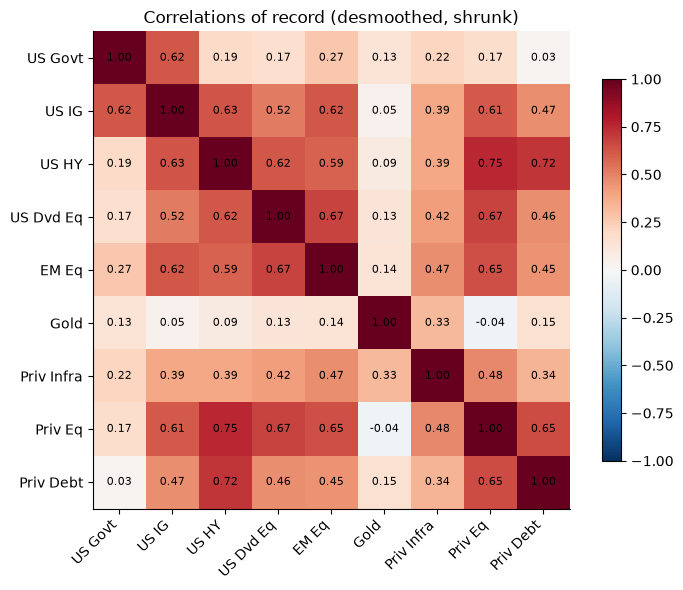

In [10]:
key = ["US Govt", "US IG", "US HY", "US Dvd Eq", "EM Eq", "Gold", "Priv Infra", "Priv Eq", "Priv Debt"]
C = state.risk.correlation.loc[key, key]
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(C.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(key)), key, rotation=45, ha="right")
ax.set_yticks(range(len(key)), key)
for i in range(len(key)):
    for j in range(len(key)):
        ax.text(j, i, f"{C.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.grid(False)
fig.colorbar(im, shrink=0.8)
ax.set_title("Correlations of record (desmoothed, shrunk)")
plt.tight_layout()
plt.show()

**What to notice:**

* **Private equity** is the riskiest sleeve once desmoothed (about 25% volatility). It is highly
  correlated with listed equities and high yield, so in risk terms it is mostly *equity beta*.
* **Private debt** has the best return per unit of risk among the growth assets, and the highest
  income (7.5%).
* **Infrastructure** combines a high return with moderate volatility and only moderate correlation
  to equities. It diversifies.
* **Gold** is almost uncorrelated with everything. It diversifies but pays no income.
* **Government bonds** have low correlation with equities and anchor the risk budget.

> **Fine print: risk model**
>
> * **Half-life.** 36 months becomes 12 quarters at the quarterly estimation frequency. The
>   covariance is annualised (×4) and bias-corrected for the uneven EWMA weights. The *effective*
>   sample (about 28 quarters) is much smaller than the nominal one, which is why shrinkage matters.
> * **Shrinkage.** A fixed 25% pull of every correlation toward the average correlation. Variances
>   are not changed.
> * **Illiquidity uplift.** Private (and gated ELTIF) volatilities ×1.15, so variances ×1.32.
>   Correlations stay the same. It is a *charge* for not being able to sell, not a statistical
>   estimate.
> * **Point in time.** The state is built from data up to the as-of date (2026-09-30). The
>   walk-forward backtest uses the same code at every past date, so there is no look-ahead.
> * **Cash volatility.** Cash shows about 0.6% volatility because its yield moved over the window. In
>   a one-period model this is a mild overstatement of cash risk.

## 5. Diagnosis of the current portfolio and feasibility of the goals

Two questions come before any optimisation:

1. **How far is today's book from the goals?**
2. **Are the goals attainable at all** with this universe and these limits? `diagnose()` computes the
   feasibility envelope *before* any target is imposed: maximum return, maximum income, minimum
   volatility, and the minimum volatility needed to reach the return goal.

In [11]:
goals = state.optimizer
w_cur = data.holdings.weights


def stats(w):
    w = np.asarray(w, float)
    return dict(
        exp_return=float(u.mu @ w),
        income=float(u.income @ w),
        vol=float(np.sqrt(w @ S.values @ w)),
        illiquid=float(w[~u.liquid_mask].sum()),
    )


print(
    f"goals: return >= {goals.target_return:.2%} | income >= {goals.target_income:.2%} today "
    f"(3.50% from 2032) | volatility {goals.vol_lo:.0%}-{goals.vol_hi:.0%}"
)
display(pct(pd.DataFrame({"current portfolio": stats(w_cur)}).T, 2))

diag = GoalOptimizer(u, S, goals).diagnose()
pd.Series(diag).to_frame("feasibility envelope")

goals: return >= 6.25% | income >= 3.46% today (3.50% from 2032) | volatility 6%-8%


,exp_return,income,vol,illiquid
current portfolio,4.97%,3.46%,3.34%,0.00%


,feasibility envelope
max_return,0.0848
max_income,0.0496
min_vol,0.0443
max_return_at_vol_hi,0.0772
max_income_at_vol_hi,0.0496
min_vol_for_return_target,0.0514
return_target_feasible,True
income_target_feasible,True


**Reading the diagnosis:**

* The current book earns about **5.0%** in expected terms, roughly 1.3% a year **short of CPI + 3%**.
  Its volatility (3.3%) is **below** the 6–8% band, so it carries too little risk to reach the goal.
* Its income (3.46%) already almost meets the goal, but only because **45% sits in cash and
  T-bills** at today's high short rates. That income is exposed to falling rates (reinvestment risk);
  it is not structural income.
* The goals **are attainable**. The return goal needs at least about 5.1% volatility, below the
  6–8% band, and the maximum income (about 5%) is well above 3.5%. The band has room to spare.

## 6. The strategic target (SAA)

### 6.1 Methodology: a goal-ordered optimiser

A classic mean-variance optimiser trades return against risk with a single risk-aversion parameter
that a client cannot interpret. The mandate instead states **goals in priority order**, so the
optimiser follows them:

For each volatility level `v` on a grid across the band (6%, 6.17%, … 8%):

1. **Maximise expected return** subject to volatility ≤ `v` and all bounds and group limits.
2. **Without giving back return** (beyond a tiny tolerance), close any **income** shortfall.
3. Recover any return still left on the table.

Then it picks the **lowest-volatility grid point that meets both the return and the income goal**.
Risk is the *budget*, not the target: the client gets the goals at the least risk. If the goals were
unreachable inside the band, a documented fallback would apply, and the output would say so.

**Constraints:** fully invested, long-only, per-asset bounds (`lb`/`ub`), group limits (e.g. equities
25–60%, private markets 6–32%, sub-IG credit 5–15%, EM exposure 6–18%), and volatility ≤ the grid
point. All of it is convex, solved with `cvxpy`/Clarabel.

> **Fine print: optimiser**
>
> * **Grid.** The band is scanned at 13 volatility levels (`vol_steps`). If the goals are already met
>   at the band floor, the answer sits **exactly at 6.0%**. Being "too safe" is not allowed: the band
>   floor is a constraint (the client asked for 6–8%).
> * **Return tolerance.** Stage 2 (income) may give back at most `return_tol` = 0.001% of return.
>   The ordering is therefore strict, not a weighted compromise.
> * **Strategic vs rebalance mode.** The *strategic* solve has no turnover cap and no trading bands:
>   it is the destination. *Today's* solve (section 11) adds the turnover cap, the no-trade band for
>   private assets and the funding-ladder floors.
> * **Fallbacks.** If the goals cannot be met inside the band, a documented fallback applies
>   (maximum return, then minimum income gap). The rule is shown in `selection_rule` and in the
>   notes, never silently.
> * **Audit.** An independent numerical re-check of every constraint (the table further down). Use
>   it to prove to a reviewer that the solution respects the policy.

In [12]:
res_free = GoalOptimizer(u, S, goals).run()
w_free = pd.Series(res_free.weights, index=u.names)
print("rule:", res_free.solution.selection_rule)
display(pct(pd.DataFrame({"optimiser, no PE floor": stats(w_free)}).T, 2))
pct(w_free[u.illiquid_names].to_frame("weight"))

rule: return+income met in band -> min risk


,exp_return,income,vol,illiquid
"optimiser, no PE floor",6.98%,4.33%,6.00%,29.00%


,weight
Priv Infra,15.0%
Priv Eq,0.0%
Priv Debt,14.0%


### 6.2 A policy decision: a strategic floor for private equity

Left alone, the optimiser holds **no private equity**. With 25% desmoothed volatility and high
correlation to listed equities, PE adds little that listed equities and high yield do not already
offer, *at these assumptions*. That is a legitimate result, but the mandate asks for a diversified
programme across private sub-strategies. There are also two reasons not to rely on a corner solution:

* **Estimation risk.** PE's desmoothed volatility rests on a short, appraisal-based history. A
  small change in φ moves it a lot.
* **Option value and lead time.** A private programme takes 4–5 years to build. Starting a small
  allocation now keeps the option to scale it up later.

So the investment committee sets a **3% minimum for private equity** (`PE_FLOOR`). The next cell
re-solves with that floor and shows what it costs. Set `PE_FLOOR = 0.0` to see the unconstrained
answer flow through the whole notebook.

In [13]:
PE_FLOOR = 0.03

assets_policy = assets.copy()
assets_policy.loc[assets_policy["name"] == "Priv Eq", "lb"] = PE_FLOOR
data = build_mandate(assets_policy)
state = StateBuilder(data).build()
u, S, goals = state.universe, state.sigma, state.optimizer

res = GoalOptimizer(u, S, goals).run()
w_saa = pd.Series(res.weights, index=u.names)
sol = res.solution
print("rule:", sol.selection_rule)
cmp = pd.DataFrame(
    {"current": stats(w_cur), "SAA without PE floor": stats(w_free), "SAA (policy)": stats(w_saa)}
).T
display(pct(cmp, 2))
print(
    f"cost of the PE floor: {stats(w_free)['exp_return'] - stats(w_saa)['exp_return']:.2%} expected return "
    f"at the same {sol.vol:.1%} volatility"
)

rule: return+income met in band -> min risk


,exp_return,income,vol,illiquid
current,4.97%,3.46%,3.34%,0.00%
SAA without PE floor,6.98%,4.33%,6.00%,29.00%
SAA (policy),6.70%,4.26%,6.00%,26.86%


cost of the PE floor: 0.28% expected return at the same 6.0% volatility


The floor costs some expected return at equal risk, because the risk budget that PE uses is taken
from infrastructure. The policy SAA still clears the return goal with a margin. The audit confirms
that every constraint holds:

In [14]:
res.audit

,check,pass,value
0,budget sums to 1,True,0.99999999
1,single-asset bounds,True,ok
2,group bounds,True,ok
3,vol <= ceiling,True,6.0000%
4,vol >= band floor,True,6.0000%
5,income target,True,4.2606%
6,return target,True,6.7012%


,current,strategic,change
Liquidity,45.0%,16.9%,-28.1%
Rates,30.0%,16.2%,-13.8%
Credit,8.0%,12.0%,4.0%
Equities,15.0%,25.0%,10.0%
Real Assets,2.0%,12.9%,10.9%
Private Markets,0.0%,17.0%,17.0%


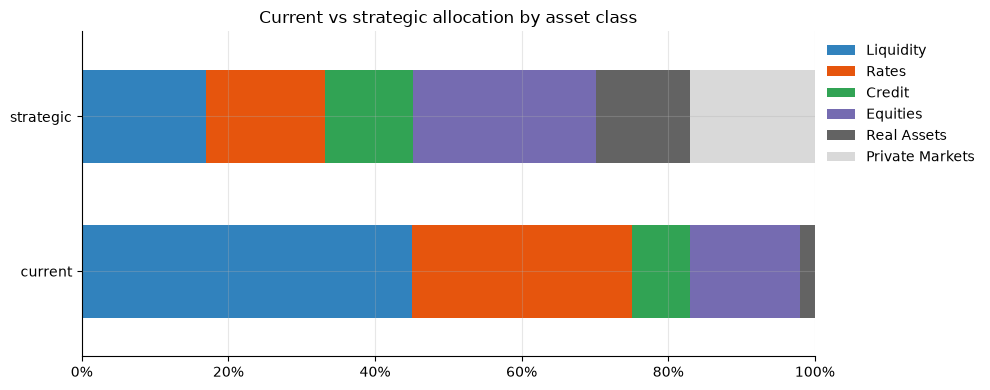

In [15]:
cls = pd.Series({a.name: a.group for a in u})
weights = pd.DataFrame({"current": pd.Series(w_cur, index=u.names), "strategic": w_saa})
by_class = (
    weights.groupby(cls)
    .sum()
    .loc[["Liquidity", "Rates", "Credit", "Equities", "Real Assets", "Private Markets"]]
)
display(pct(by_class.assign(change=by_class["strategic"] - by_class["current"])))

fig, ax = plt.subplots(figsize=(10, 4))
by_class.T.plot.barh(stacked=True, ax=ax, colormap="tab20c", width=0.6)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title("Current vs strategic allocation by asset class")
ax.legend(bbox_to_anchor=(1, 1), frameon=False)
plt.tight_layout()
plt.show()

### 6.3 The strategic target in words

| | Current | Strategic | Why |
|---|---|---|---|
| **Liquidity** | 45% | ≈ 17% | Cash is the drag on return. What remains is a deliberate pool at a high short-term yield that also funds capital calls. |
| **Rates** | 30% | ≈ 16% | Smaller, but split between US Treasuries and UK gilts. The equity hedge stays. |
| **Credit** | 8% | 12% | IG plus a sub-IG sleeve (HY, EM hard currency) for income |
| **Equities** | 15% | 25% | Global instead of US-only, at the 25% policy minimum |
| **Real assets** | 2% | ≈ 13% | Gold at its floor, plus infrastructure (inflation-linked cash flows) |
| **Private markets** | 0% | 17% | Private debt at its 14% cap (income engine) plus 3% PE |

The full asset-level target:

In [16]:
tgt = pd.DataFrame({"class": cls, "current": w_cur, "strategic": w_saa})
tgt = tgt[(tgt["current"] > 1e-4) | (tgt["strategic"] > 1e-4)]
pct(tgt.assign(change=tgt["strategic"] - tgt["current"]))

,class,current,strategic,change
Cash,Liquidity,45.0%,16.9%,-28.1%
US Govt,Rates,30.0%,8.2%,-21.8%
UK Govt,Rates,0.0%,8.0%,8.0%
EM HC,Credit,0.0%,3.0%,3.0%
US IG,Credit,8.0%,3.0%,-5.0%
EU IG,Credit,0.0%,4.0%,4.0%
US HY,Credit,0.0%,2.0%,2.0%
US Dvd Eq,Equities,7.0%,10.0%,3.0%
US Nasdaq Eq,Equities,8.0%,0.0%,-8.0%
EU ex UK Eq,Equities,0.0%,2.0%,2.0%


## 7. Why this allocation, and how robust is it?

### 7.1 What private markets add: efficient frontiers

`reference_frontiers` traces the maximum expected return at each volatility for three universes:

* **policy**: all limits, private sleeves allowed;
* **no privates**: the same limits, with the private sleeves set to zero;
* **unconstrained**: long-only and fully invested only.

The vertical gap between *policy* and *no privates* is **what private markets add at equal risk**.
The gap to *unconstrained* is **the cost of the policy limits**.

,policy,no_privates,unconstrained,privates_add,policy_cost
vol,,,,,
0.0600,6.70%,6.14%,8.39%,0.56%,1.69%
0.0700,7.36%,6.50%,8.99%,0.87%,1.63%
0.0800,7.72%,6.80%,9.38%,0.93%,1.66%


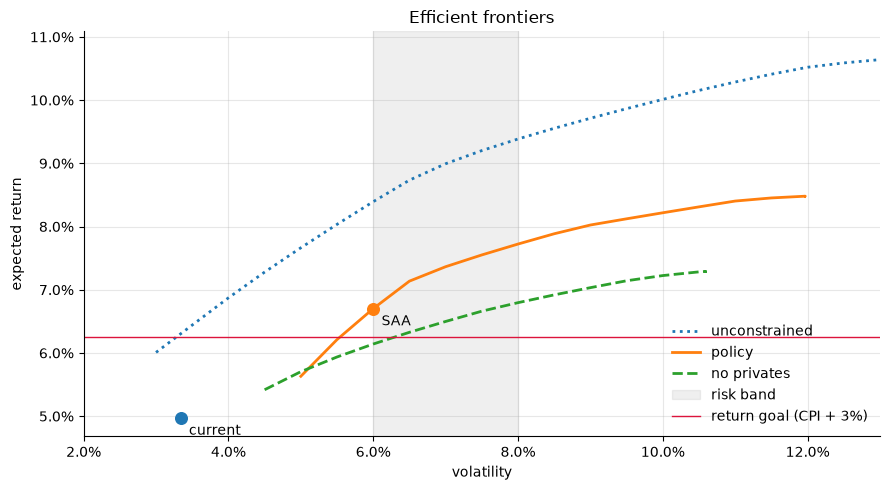

In [17]:
fronts = frontier.reference_frontiers(u, S, config=goals)
gaps = frontier.frontier_gaps(fronts, [0.06, 0.07, 0.08])
display(pct(gaps, 2))

fig, ax = plt.subplots(figsize=(9, 5))
for k, style in (("unconstrained", ":"), ("policy", "-"), ("no_privates", "--")):
    f = fronts[k]
    ax.plot(f["vol"], f["exp_return"], style, lw=2, label=k.replace("_", " "))
ax.axvspan(goals.vol_lo, goals.vol_hi, color="grey", alpha=0.12, label="risk band")
ax.axhline(goals.target_return, color="crimson", lw=1, label="return goal (CPI + 3%)")
for name, w in (("current", w_cur), ("SAA", w_saa.values)):
    s = stats(w)
    ax.scatter(s["vol"], s["exp_return"], s=70, zorder=5)
    ax.annotate(name, (s["vol"], s["exp_return"]), xytext=(6, -12), textcoords="offset points")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlabel("volatility")
ax.set_ylabel("expected return")
ax.set_xlim(0.02, 0.13)
ax.set_title("Efficient frontiers")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

Without private markets, the best policy portfolio at 6% volatility **falls short** of the return
goal (about 6.1% against 6.25%). With them, the same risk earns roughly 0.6% to 0.9% a year more,
depending on the risk level. That is the case for building a private programme despite its illiquidity.

### 7.2 Where the risk comes from

Capital weights are misleading. 25% in equities produces about half of the portfolio's risk.
`risk.attribution` splits volatility into contributions that sum to 100%.

In [18]:
ports = {"current": w_cur, "strategic": w_saa.values}
att = risk.attribution(ports, S, u)
by = risk.attribution_by(att, u).pivot(
    index="asset_class", columns="portfolio", values=["weight", "pct_of_risk"]
)
display(pct(by))
pct(
    risk.concentration(ports, S, u)[
        [
            "vol",
            "diversification_ratio",
            "effective_n_weight",
            "effective_n_risk",
            "largest_risk",
            "largest_risk_share",
        ]
    ],
    2,
)

weight           pct_of_risk          
portfolio       current strategic     current strategic
asset_class                                            
Credit             8.0%     12.0%       13.3%      9.8%
Equities          15.0%     25.0%       57.3%     52.3%
Liquidity         45.0%     16.9%        3.4%      0.8%
Private Markets    0.0%     17.0%        0.0%     20.5%
Rates             30.0%     16.2%       24.8%      3.0%
Real Assets        2.0%     12.9%        1.1%     13.6%

,vol,diversification_ratio,effective_n_weight,effective_n_risk,largest_risk,largest_risk_share
current,3.34%,139.30%,321.96%,378.40%,US Nasdaq Eq,38.54%
strategic,6.00%,140.46%,1093.58%,1099.32%,US Dvd Eq,16.59%


The strategic portfolio spreads risk across about **11 effective positions instead of 4**, and no
single sleeve contributes more than about a sixth of the risk. The current book is dominated by the
US Nasdaq sleeve, which carries close to 40% of its (small) risk.

### 7.3 Income: does the SAA meet 3.5% by 2032, and from which sources?

In [19]:
W = pd.DataFrame(ports, index=u.names).T
pct(liquidity.income_decomposition(W, u, 0.035), 2)

,Credit,Equities,Liquidity,Private Markets,Rates,Real Assets,total,target,gap
current,0.44%,0.22%,1.66%,0.00%,1.14%,0.00%,3.46%,3.50%,-0.04%
strategic,0.63%,0.68%,0.63%,1.12%,0.66%,0.55%,4.26%,3.50%,0.76%


The SAA yields about **4.3%**, comfortably above the 3.5% goal. More importantly, the income moves
from cash (which reprices as soon as short rates fall) to **structural** sources: private debt,
credit, infrastructure and dividend equities.

### 7.4 Sensitivity: what if the assumptions are wrong?

`sensitivity.sensitivity` re-solves the strategic problem under shifted assumptions: return
assumptions ±1% per asset class, covariance ×0.8/×1.2, goals ±0.5%, risk band ±1%. A robust SAA
should keep meeting the goals with modest turnover. `binding_constraints` lists the limits that are
active at the optimum. These are the limits worth discussing first, because they shape the answer.

In [20]:
summ, _ = sensitivity.sensitivity(u, S, goals)
display(pct(summ[["exp_return", "income", "vol", "turnover"]], 2).assign(largest_move=summ["largest_move"]))
sensitivity.binding_constraints(w_saa.values, u)

,exp_return,income,vol,turnover,largest_move
case,,,,,
base,6.70%,4.26%,6.00%,0.00%,
CMA Credit +1.0%,6.83%,4.22%,6.00%,6.00%,EU IG +6.0%
CMA Credit -1.0%,6.58%,4.26%,6.00%,0.00%,US Govt +0.0%
CMA Equities +1.0%,6.95%,4.26%,6.00%,0.00%,US Govt -0.0%
CMA Equities -1.0%,6.45%,4.26%,6.00%,0.00%,US Govt -0.0%
CMA Liquidity +1.0%,6.93%,4.25%,6.00%,8.20%,Cash +7.3%
CMA Liquidity -1.0%,6.65%,4.12%,6.00%,16.61%,Cash -14.9%
CMA Private Markets +1.0%,6.87%,4.26%,6.00%,0.00%,US Govt -0.0%
CMA Private Markets -1.0%,6.54%,4.08%,6.00%,6.21%,Priv Debt -6.2%


,constraint,side,limit,value
0,asset UK Govt,upper,0.0800,0.0800
1,asset EM HC,lower,0.0300,0.0300
2,asset US IG,lower,0.0300,0.0300
3,asset EU ex UK Eq,lower,0.0200,0.0200
4,asset EU Dvd Eq,lower,0.0200,0.0200
5,asset UK Eq,lower,0.0200,0.0200
6,asset Pac ex JP Eq,lower,0.0100,0.0100
7,asset EM Eq,lower,0.0300,0.0300
8,asset Gold,lower,0.0300,0.0300
9,asset Priv Eq,lower,0.0300,0.0300


**Reading the sensitivity:** across every case the return and income goals are still met (rule
unchanged). Most cases need less than 10% turnover. The largest swings come from the **cash and
rates assumptions**: if cash yields fall 1%, the optimiser moves out of cash into longer assets.
Private-market allocations are sticky, which is good, because they cannot be changed quickly.

The **binding** constraints show that the SAA leans on *diversification floors* (minimum weights in
EM, non-US equities, gold, credit) and on the **private debt cap**. The investment committee should
consciously confirm these limits, because they shape the answer as much as the assumptions do.

## 8. Implementation framework: allocations within each asset class

The optimiser decides the **public** sleeves directly. For the **private** sleeves the data has one
index per sleeve, so the split into sub-strategies is a **policy decision** (manager and vintage
diversification, J-curve management), not an optimisation output. The private splits below are the
proposed implementation policy.

In [21]:
pub = pd.DataFrame({"class": cls, "weight": w_saa})
pub = pub[(~pub.index.isin(u.illiquid_names)) & (pub["weight"] > 1e-4)]
pub["share_of_class"] = pub["weight"] / pub.groupby("class")["weight"].transform("sum")
pct(pub.sort_values(["class", "weight"], ascending=[True, False]))

,class,weight,share_of_class
EU IG,Credit,4.0%,33.3%
EM HC,Credit,3.0%,25.0%
US IG,Credit,3.0%,25.0%
US HY,Credit,2.0%,16.7%
US Dvd Eq,Equities,10.0%,40.0%
JP Eq,Equities,5.0%,20.0%
EM Eq,Equities,3.0%,12.0%
UK Eq,Equities,2.0%,8.0%
EU ex UK Eq,Equities,2.0%,8.0%
EU Dvd Eq,Equities,2.0%,8.0%


In [22]:
sub_policy = {
    "Priv Debt": {
        "Direct lending (senior, sponsor-backed)": 0.60,
        "Syndicated / broadly syndicated loans": 0.20,
        "Opportunistic & special situations credit": 0.20,
    },
    "Priv Eq": {"Buyout (small/mid)": 0.45, "Secondaries": 0.30, "Growth equity": 0.15, "Venture": 0.10},
    "Priv Infra": {"Core": 0.50, "Core-plus": 0.35, "Value-add": 0.15},
}
rows = []
for sleeve, split in sub_policy.items():
    for sub, share in split.items():
        rows.append(
            dict(
                sleeve=sleeve,
                sub_strategy=sub,
                share_of_sleeve=share,
                portfolio_weight=share * w_saa[sleeve],
                usd_at_target=share * w_saa[sleeve] * PV0,
            )
        )
sub = pd.DataFrame(rows).set_index(["sleeve", "sub_strategy"])
sub.assign(
    share_of_sleeve=pct(sub[["share_of_sleeve"]])["share_of_sleeve"],
    portfolio_weight=pct(sub[["portfolio_weight"]], 2)["portfolio_weight"],
    usd_at_target=mio(sub[["usd_at_target"]])["usd_at_target"],
)

share_of_sleeve portfolio_weight usd_at_target
sleeve     sub_strategy                                                                            
Priv Debt  Direct lending (senior, sponsor-backed)             60.0%            8.40%           8.4
           Syndicated / broadly syndicated loans               20.0%            2.80%           2.8
           Opportunistic & special situations credit           20.0%            2.80%           2.8
Priv Eq    Buyout (small/mid)                                  45.0%            1.35%           1.3
           Secondaries                                         30.0%            0.90%           0.9
           Growth equity                                       15.0%            0.45%           0.4
           Venture                                             10.0%            0.30%           0.3
Priv Infra Core                                                50.0%            4.93%           4.9
           Core-plus                                           35.0%            3.45%           3.5
           Value-add                                           15.0%            1.48%           1.5

**Rationale for the private sub-strategies:**

* **Private debt (income engine, 14%).** Mostly *senior direct lending*: floating-rate, a high cash
  yield and low loss rates. *Syndicated loans* are liquid and can be bought immediately, so they act
  as the **interim exposure** while direct-lending commitments are drawn. *Opportunistic credit* adds
  upside in stressed markets.
* **Private equity (3%).** At USD 100m the PE budget (about USD 3m of NAV) is too small for a
  diversified set of primary funds. **Secondaries** (bought mid-life, so they shorten the J-curve and
  deploy fast) and a **fund-of-funds or evergreen vehicle** for buyout/growth/venture give vintage
  and manager diversification with small tickets.
* **Infrastructure (real asset, about 10%).** Core-heavy for inflation-linked, contracted cash yield
  (the income goal). Core-plus and value-add add return.
* **Public debt.** Treasuries remain the core (duration and liquidity, and the ladder for later
  calls), diversified into UK government bonds. Credit is split between IG (US/EU) and a sub-IG sleeve
  (US HY, EM hard currency).
* **Equities.** Moves from a US-only, growth-heavy book to a **global** one with a quality/dividend
  tilt (US dividend), regional diversification (Europe, UK, Japan, Pacific, EM) and no single-name
  growth concentration.

## 9. Commitment pacing plan for private and real assets

### 9.1 The problem

Private funds cannot be bought at NAV. You **commit** an amount, the manager **calls** it over 2–4
years, and **distributes** it back as investments are realised. To *hold* about 27% of a growing
portfolio in private assets, you have to commit far more than 27% over time, because early vintages
are already paying back while later ones are still drawing.

### 9.2 The pacing model (Takahashi–Alexander)

Each commitment (a *vintage*) follows a standard cash-flow model, with parameters in `pacing.csv`:

* **Calls:** a contribution rate per year applied to the *remaining* commitment, e.g. 40% → 60% →
  100% for infrastructure. Only `drawdown_ratio` (85–90%) of a commitment is ever called.
* **Growth:** NAV grows at the sleeve's expected return.
* **Distributions:** the yield (income) plus a fraction `(age / life) ** bow` of NAV. A higher bow
  factor means later distributions.

Here is the profile of a commitment of 1.0 in each sleeve:

In [23]:
prof = pd.concat(
    {
        n: single_vintage_profile(state.pacing[n]).loc[1:8, ["call", "distribution", "nav"]]
        for n in u.illiquid_names
    },
    axis=1,
)
display(prof.round(3))
pd.DataFrame(
    {
        n: {
            "life (y)": p.life_years,
            "commitment period (y)": p.commitment_period,
            "contribution rates": p.contribution_rates,
            "bow": p.bow_factor,
            "growth = exp. return": round(p.growth_rate, 4),
            "yield = income": round(p.yield_rate, 4),
            "drawdown ratio": p.drawdown_ratio,
        }
        for n, p in state.pacing.items()
    }
)

Priv Infra                     Priv Eq                     Priv Debt                    
          call distribution    nav    call distribution    nav      call distribution    nav
age                                                                                         
1       0.3600       0.0000 0.3600  0.2250       0.0000 0.2250    0.4250       0.0000 0.4250
2       0.3240       0.0360 0.6860  0.3380       0.0080 0.5800    0.4250       0.1340 0.7500
3       0.2160       0.1060 0.8670  0.2530       0.0350 0.8640    0.0000       0.3490 0.4600
4       0.0000       0.2010 0.7560  0.0840       0.0930 0.9540    0.0000       0.2880 0.2080
5       0.0000       0.2500 0.5840  0.0000       0.1730 0.8890    0.0000       0.1660 0.0590
6       0.0000       0.2640 0.3800  0.0000       0.2560 0.7330    0.0000       0.0570 0.0060
7       0.0000       0.2270 0.1930  0.0000       0.3170 0.5000    0.0000       0.0070 0.0000
8       0.0000       0.1470 0.0660  0.0000       0.3090 0.2470    0.0000       0.0000 0.0000

,Priv Eq,Priv Infra,Priv Debt
life (y),10,10,7
commitment period (y),4,3,2
contribution rates,"(0.25, 0.5, 0.75, 1.0)","(0.4, 0.6, 1.0)","(0.5, 1.0)"
bow,2.8000,2.0000,1.2000
growth = exp. return,0.1135,0.1040,0.0790
yield = income,0.0220,0.0555,0.0750
drawdown ratio,0.9000,0.9000,0.8500


### 9.3 Solving for the pacing plan

We need commitments that make each sleeve's NAV follow a **target path**:

$$ \text{NAV}^{\text{target}}_{s,t} = w^{\text{SAA}}_s \cdot PV_0 \,(1+g)^t \cdot \min\left(1, \tfrac{t}{5}\right) $$

so each sleeve reaches its strategic weight of a portfolio that grows at its expected return `g`,
ramping up linearly over **5 years** (by 2031, ahead of the 2032 income date).

The pacing model is **linear** in the amounts, so the plan can be solved with non-negative least
squares in two steps:

1. **Calls.** Find the yearly capital calls `c ≥ 0` whose resulting NAV (simulated with the same
   monthly private book the engine uses) tracks the target: minimise ‖A·c − target‖² + λ‖Δc‖². The
   second term keeps the calls smooth from year to year (vintage diversification).
2. **Commitments.** Find the yearly commitments `k ≥ 0` whose contractual call pattern
   (contribution rates × drawdown ratio) produces those calls: minimise ‖B·k − c‖² + λ‖Δk‖².

The fit runs over 15 years so that late vintages are pinned down too. We report the first 10 years.

> **Fine print: pacing**
>
> * **Two models of one programme.** Commitments → calls follow the *vintage* model (contribution
>   rates on the remaining commitment, times the drawdown ratio). Calls → NAV and distributions
>   follow the engine's *monthly book*, in which each paid call ages from its call date. Both are
>   Takahashi–Alexander. The two-step solve keeps them consistent, so the transition plan, the
>   J-curve and the IRRs all use the same calls.
> * **Drawdown ratio.** Only 85–90% of a commitment is ever called. The remaining 10–15% expires
>   undrawn, so commitments must be **larger** than the target NAV path implies.
> * **Growth = expected return.** Private NAV grows at the sleeve's expected return. Each vintage's
>   IRR therefore equals the assumption (a consistency check, section 10). Real funds show dispersion
>   around it; manager selection is not modelled.
> * **Annual granularity.** Calls are placed at each anniversary of the as-of date (end of
>   September). Real calls arrive monthly. That matters for the size of the cash buffer, not for the
>   strategy.
> * **Smoothing λ = 0.3.** This trades a perfect NAV fit against steady commitments (vintage
>   diversification). λ = 0 fits the target exactly but gives erratic, sometimes zero, commitments.
> * **Re-pacing.** The plan is a *forecast*. In practice it is re-solved every year from the actual
>   NAV, undrawn amounts and distributions, and only the next year's commitments are signed.

In [24]:
H, H_FIT, RAMP = 10, 15, 5
g_port = stats(w_saa)["exp_return"]
priv = u.illiquid_names
yrs = np.arange(1, H_FIT + 1)


def unit_call_response(p, n_years):
    # NAV / distributions at each year-end from a call of 1 paid at year-end j (engine's monthly book)
    nav, dist = np.zeros((n_years, n_years)), np.zeros((n_years, n_years))
    g = monthly_growth(p.growth_rate)
    for j in range(n_years):
        book = PrivateBook("unit", p)
        book.call_now(1.0)
        nav[j, j] = 1.0
        for t in range(j + 1, n_years):
            d = sum(book.step_month(g)[1] for _ in range(12))
            nav[t, j], dist[t, j] = book.nav, d
    return nav, dist


def smooth_nnls(A, b, lam):
    n = A.shape[1]
    D = lam * np.abs(A).max() * np.diff(np.eye(n), axis=0)
    x, _ = nnls(np.vstack([A, D]), np.concatenate([b, np.zeros(n - 1)]))
    return x


commitments, calls, dists, navs, targets = {}, {}, {}, {}, {}
for n in priv:
    p = state.pacing[n]
    A_nav, A_dist = unit_call_response(p, H_FIT)
    target = w_saa[n] * PV0 * (1 + g_port) ** yrs * np.minimum(1.0, yrs / RAMP)
    c_star = smooth_nnls(A_nav, target, 0.3)  # step 1: calls
    B = np.column_stack(
        [simulate_pacing([0.0] * v + [1.0], p, horizon=H_FIT + 1)["call"].values[1:] for v in range(H_FIT)]
    )  # calls from a commitment in year v
    k = np.round(smooth_nnls(B, c_star, 0.3), -5)  # step 2: commitments, USD 0.1m
    c = np.round(B @ k, -4)  # calls implied by those commitments
    commitments[n], calls[n], dists[n], navs[n], targets[n] = k, c, A_dist @ c, A_nav @ c, target

years = pd.Index([data.asof.year + i for i in range(H)], name="commitment year (from Q4)")
commit_tbl = pd.DataFrame({n: commitments[n][:H] for n in priv}, index=years)
commit_tbl["total"] = commit_tbl.sum(axis=1)
print("COMMITMENT PLAN (USD m, signed during the year starting in Q4 of the year shown)")
mio(commit_tbl)

COMMITMENT PLAN (USD m, signed during the year starting in Q4 of the year shown)


,Priv Infra,Priv Eq,Priv Debt,total
commitment year (from Q4),,,,
2026,3.4,1.3,3.4,8.1
2027,2.7,0.7,3.7,7.1
2028,2.1,0.6,5.1,7.8
2029,3.9,1.1,6.4,11.4
2030,3.9,0.9,9.2,14.0
2031,2.9,0.2,8.5,11.6
2032,1.2,0.1,7.5,8.8
2033,3.6,0.9,9.1,13.6
2034,4.4,1.1,9.9,15.4


In [25]:
yr_end = pd.Index(
    [f"{data.asof + pd.DateOffset(years=int(t)):%Y-%m}" for t in range(1, H + 1)], name="year ending"
)
cf_tbl = pd.DataFrame(
    {
        "commitments": sum(commitments[n][:H] for n in priv),
        "calls": sum(calls[n][:H] for n in priv),
        "distributions": sum(dists[n][:H] for n in priv),
    },
    index=yr_end,
)
cf_tbl["net_cash_flow"] = cf_tbl["distributions"] - cf_tbl["calls"]
cf_tbl["cum_net_cash_flow"] = cf_tbl["net_cash_flow"].cumsum()
cf_tbl["private_nav"] = sum(navs[n][:H] for n in priv)
cf_tbl["target_nav"] = sum(targets[n][:H] for n in priv)
print("PROGRAMME CASH FLOWS (USD m)")
mio(cf_tbl)

PROGRAMME CASH FLOWS (USD m)


,commitments,calls,distributions,net_cash_flow,cum_net_cash_flow,private_nav,target_nav
year ending,,,,,,,
2027-09,8.1,5.7,0.0,-5.7,-5.7,5.7,5.7
2028-09,7.1,6.8,0.7,-6.1,-11.8,12.3,12.2
2029-09,7.8,8.3,1.9,-6.4,-18.2,19.7,19.6
2030-09,11.4,10.5,3.7,-6.8,-25.0,28.2,27.9
2031-09,14.0,11.3,5.9,-5.4,-30.4,36.0,37.2
2032-09,11.6,9.4,8.4,-1.0,-31.5,40.0,39.6
2033-09,8.8,9.7,10.5,0.8,-30.6,42.4,42.3
2034-09,13.6,11.7,12.2,0.6,-30.1,45.2,45.1
2035-09,15.4,12.9,13.6,0.7,-29.4,48.1,48.2


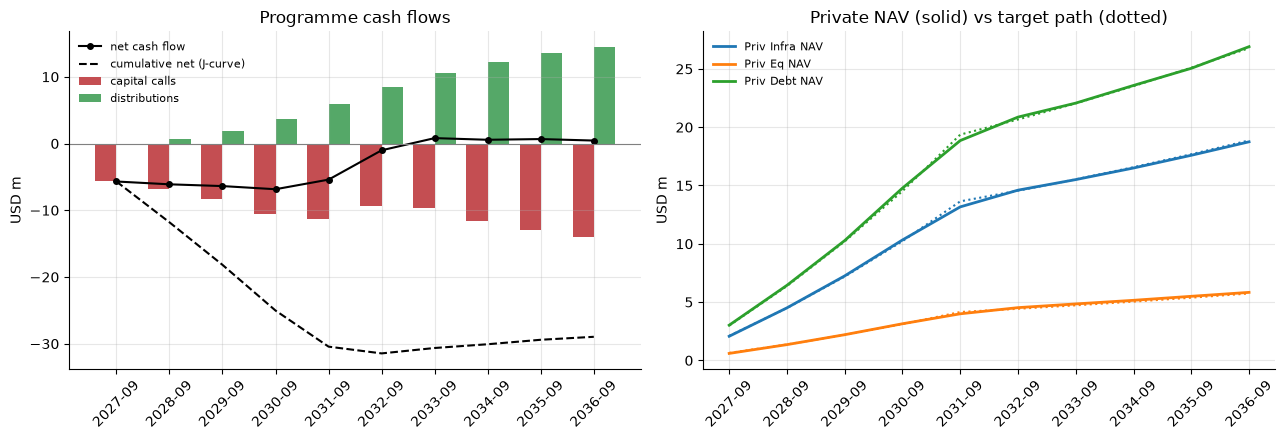

In [26]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
x = np.arange(H)
ax1.bar(x - 0.2, cf_tbl["calls"] / 1e6 * -1, 0.4, label="capital calls", color="#c44e52")
ax1.bar(x + 0.2, cf_tbl["distributions"] / 1e6, 0.4, label="distributions", color="#55a868")
ax1.plot(x, cf_tbl["net_cash_flow"] / 1e6, "k-o", ms=4, label="net cash flow")
ax1.plot(x, cf_tbl["cum_net_cash_flow"] / 1e6, "k--", label="cumulative net (J-curve)")
ax1.set_xticks(x, yr_end, rotation=45)
ax1.set_ylabel("USD m")
ax1.axhline(0, color="grey", lw=0.8)
ax1.set_title("Programme cash flows")
ax1.legend(frameon=False, fontsize=8)
for n in priv:
    ax2.plot(x, navs[n][:H] / 1e6, lw=2, label=f"{n} NAV")
    ax2.plot(x, targets[n][:H] / 1e6, ":", color=ax2.lines[-1].get_color())
ax2.set_xticks(x, yr_end, rotation=45)
ax2.set_ylabel("USD m")
ax2.set_title("Private NAV (solid) vs target path (dotted)")
ax2.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

**Reading the pacing plan:**

* **Steady build.** Commitments start at about USD 7–8m a year and rise to about USD 14m by year 5
  (about USD 48m over the first five years). They grow with the portfolio, and private debt (the
  largest sleeve, with the shortest fund life) needs the most re-commitment.
* **J-curve.** Net cash flow is negative for the first six years (calls exceed distributions). The
  cumulative trough, about USD 31m, is the **liquidity the rest of the portfolio must supply**.
  Section 11 shows it is covered.
* **Self-funding.** From about year 7, distributions match calls and the programme is roughly
  **self-funding**: new commitments are paid from old distributions.
* **NAV tracks target.** Private NAV follows the target path closely and reaches the strategic
  weights around 2031.
* **Ticket sizes.** Private-equity commitments are about USD 1m a year, below typical fund
  minimums. This confirms the implementation choice of secondaries and fund-of-funds or evergreen
  vehicles (section 8).

### 9.4 The capital-call schedule used by the engine

The plan becomes the call schedule (`commitment_future`) of the mandate. The **funding ladder** is
sized on **net** calls (calls minus the same sleeve's distributions from the year before). That is
the cash the rest of the portfolio must actually provide, since distributions are swept into cash
and fund later calls.

In [27]:
asof = data.asof
call_rows, net_rows = [], []
for n in priv:
    for i in range(H):
        d = f"{asof + pd.DateOffset(years=i + 1) + pd.offsets.MonthEnd(0):%Y-%m-%d}"
        if calls[n][i] > 0:
            call_rows.append(dict(date=d, asset=n, amount=float(calls[n][i])))
        net = calls[n][i] - (dists[n][i - 1] if i else 0.0)
        if net > 0:
            net_rows.append(dict(date=d, asset=n, amount=float(round(net, -4))))
schedule = pd.DataFrame(call_rows)  # what is actually paid
net_schedule = pd.DataFrame(net_rows)  # what the funding ladder pre-funds

print("Gross capital calls (USD m) - paid on these dates:")
display(mio(schedule.pivot_table(index="date", columns="asset", values="amount", aggfunc="sum").fillna(0.0)))
print("Net calls pre-funded by the ladder (USD m):")
mio(net_schedule.pivot_table(index="date", columns="asset", values="amount", aggfunc="sum").fillna(0.0))

Gross capital calls (USD m) - paid on these dates:


asset,Priv Debt,Priv Eq,Priv Infra
date,,,
2027-09-30,3.0,0.6,2.1
2028-09-30,3.7,0.7,2.4
2029-09-30,4.9,0.7,2.7
2030-09-30,6.6,0.8,3.1
2031-09-30,7.5,0.7,3.1
2032-09-30,6.8,0.4,2.2
2033-09-30,7.1,0.4,2.3
2034-09-30,8.1,0.6,3.0
2035-09-30,8.5,0.9,3.5


Net calls pre-funded by the ladder (USD m):


asset,Priv Debt,Priv Eq,Priv Infra
date,,,
2027-09-30,3.0,0.6,2.1
2028-09-30,3.7,0.7,2.4
2029-09-30,4.3,0.7,2.5
2030-09-30,5.1,0.7,2.7
2031-09-30,4.7,0.6,2.4
2032-09-30,2.4,0.2,0.9
2033-09-30,1.0,0.0,0.3
2034-09-30,0.8,0.1,0.2
2035-09-30,0.5,0.1,0.1


## 10. Private-markets performance: J-curve, IRR, TVPI

`private_markets.project_cashflows` runs every scheduled call as its own cohort on the monthly book
and measures the programme like an LP would: **DPI** (distributions / paid-in), **TVPI** (total
value / paid-in) and **IRR**. Because the pacing model grows NAV at the expected return, each
sleeve's IRR should be close to its expected return. That is a built-in **consistency check** between
the pacing plan and the optimiser's assumptions.

In [28]:
cf = private_markets.project_cashflows(state.pacing, schedule, asof)
perf = private_markets.performance(cf, ("asset",)).set_index("asset")
perf["exp_return (CMA)"] = [u[n].exp_return for n in perf.index]
display(
    perf.assign(**{c: mio(perf[[c]])[c] for c in ("paid_in", "distributions", "final_nav")}).round(
        {"dpi": 2, "rvpi": 2, "tvpi": 2, "irr": 4}
    )
)
print("effective number of vintages (1/HHI of NAV by cohort):")
private_markets.vintage_diversification(cf)["effective_vintages"].loc[asof.year + 1 : asof.year + 10].round(
    1
).to_frame().T

,paid_in,distributions,final_nav,dpi,rvpi,tvpi,irr,exp_return (CMA)
asset,,,,,,,,
Priv Debt,65.5,79.0,0.0,1.2100,0.0000,1.2100,0.0789,0.0790
Priv Eq,6.7,12.8,0.0,1.9000,0.0000,1.9000,0.1134,0.1135
Priv Infra,28.3,44.3,0.0,1.5700,0.0000,1.5700,0.1039,0.1040


effective number of vintages (1/HHI of NAV by cohort):


year,2027,2028,2029,2030,2031,2032,2033,2034,2035,2036
effective_vintages,1.0000,2.0000,2.9000,3.5000,4.1000,4.8000,5.4000,5.5000,5.4000,5.1000


## 11. Portfolio transition

### 11.1 Two portfolios: *strategic* vs *today*

The strategic target holds about 27% in private assets, but **you cannot buy that today**. The
private sleeves can only be built through commitments over the next 4–5 years. `saa-pm` therefore
separates:

* **Strategic target:** where the portfolio *should* be (sections 6–8).
* **Today's portfolio:** what is **implementable now**. The private sleeves are pinned at their
  current NAV (zero), the **funding ladder** holds enough liquid assets for the net calls by due
  date, and the liquid book is optimised for the same ranked goals.

**Funding ladder.** Net calls are pre-funded by when they fall due:

* **Bucket 1** (calls within 2 years): Cash.
* **Bucket 2** (2–3 years): T-bills.
* **Bucket 3** (beyond 3 years): IG credit and Treasuries.

This avoids forced sales of risky assets when calls arrive in a falling market.

In [29]:
data_t = build_mandate(assets_policy, net_schedule)  # the ladder is sized on the NET schedule
alloc = PointInTimeAllocator(data_t).run()

summ = alloc.summary()
display(
    pct(summ[["exp_return", "income", "vol", "illiquid", "turnover_vs_current"]].astype(float), 2).assign(
        rule=summ["rule"].fillna("")
    )
)
display(alloc.ladder_table.assign(need_ccy=lambda d: d["need_ccy"] / 1e6).round(3))
for note in alloc.notes:
    print("note:", note)

,exp_return,income,vol,illiquid,turnover_vs_current,rule
current,4.97%,3.46%,3.34%,0.00%,0.00%,
strategic,6.70%,4.26%,6.00%,26.86%,62.86%,return+income met in band -> min risk
today,5.76%,3.46%,5.87%,0.00%,30.00%,"targets unreachable -> max return, then min in..."


,bucket,assets,window,need_pct_pv,need_ccy,held_pct_pv,cover
0,1,Cash,0y <= t < 2y,0.0570,5.6900,0.2000,3.5150
1,2,US STR,2y <= t < 3y,0.0680,6.8100,0.0680,1.0000
2,3,US Govt|US IG,t >= 3y,0.3120,31.1600,0.3300,1.0590


note: group 'Private Markets' floor 6.00% unreachable (max 0.00%) - lowered
note: today audit: vol >= band floor: 5.8685%
note: today audit: return target: 5.7605%


**Reading the result:**

* **Today's portfolio** lifts expected return from about 5.0% to about 5.8%. It does **not yet reach
  CPI + 3%**, and its volatility (5.9%) stays just below the band, so the optimiser reports
  `targets unreachable → max return`. That is expected and honest, for two reasons:
  * The **turnover cap binds.** The mandate allows 30% one-way turnover per rebalance, and today's
    portfolio uses exactly 30%. The repositioning therefore continues at the next rebalance (see the
    sequencing in 11.4).
  * The private sleeves, which carry much of the strategic return, can only be built through calls.
    The gap closes as the programme is called (section 11.3).
* The **ladder** holds the net calls of the coming years in cash, T-bills and IG/Treasuries, with
  cover ≥ 1 in every bucket.

> **Fine print: today's portfolio and the ladder**
>
> * **Privates pinned.** Closed-end sleeves are fixed at their current NAV (here 0%), within a
>   ±1% no-trade band. A private floor (e.g. Priv Debt ≥ 2%, or the Private Markets group ≥ 6%) that
>   cannot be reached today is **lowered** and reported in the notes.
> * **Net, not gross.** The ladder is sized on *net* calls. Sizing on gross calls (USD 100m over
>   10 years) would demand more than the whole IG/Treasury allocation and ignore that distributions
>   pay later calls.
> * **Buckets by due date.** Calls due within 2 years go to cash, 2–3 years to T-bills, and later
>   ones to IG/Treasuries. Longer-dated calls can be pre-funded in higher-yielding assets.
> * **Cover.** `ladder_cover` = 1.0 pre-funds 100% of the net calls; 1.2 would add a 20% buffer.
>   Bucket 1 holds more (cover 3.5×) because the optimiser keeps cash for its own reasons (yield,
>   low risk).
> * **Transaction costs.** Each asset's `tx_cost_bps` is charged on the traded amount. At about
>   2 bp of assets, costs are negligible next to the timing risk of the trade.

### 11.2 Trades for the initial rebalance

In [30]:
wt = alloc.weights()
trades = pd.DataFrame({"current": wt["current"], "today": wt["today"], "strategic": wt["strategic"]})
trades["trade_usd"] = (trades["today"] - trades["current"]) * PV0
tx_bps = pd.Series({a.name: a.tx_cost_bps for a in u})
trades["cost_usd"] = trades["trade_usd"].abs() * tx_bps / 1e4
trades = trades[(trades[["current", "today", "strategic"]].abs().sum(axis=1) > 1e-4)]
print(
    f"one-way turnover {0.5 * (wt['today'] - wt['current']).abs().sum():.1%}, "
    f"estimated transaction cost USD {trades['cost_usd'].sum():,.0f} "
    f"({trades['cost_usd'].sum() / PV0:.2%} of assets)"
)
trades.assign(
    **{c: pct(trades[[c]])[c] for c in ("current", "today", "strategic")},
    trade_usd=mio(trades[["trade_usd"]], 2)["trade_usd"],
    cost_usd=trades["cost_usd"].round(0),
)

one-way turnover 30.0%, estimated transaction cost USD 22,838 (0.02% of assets)


,current,today,strategic,trade_usd,cost_usd
Cash,45.0%,20.0%,16.9%,-25.00,0.0000
US STR,0.0%,6.8%,0.0%,6.81,681.0000
US Govt,30.0%,25.0%,8.2%,-5.00,"1,000.0000"
UK Govt,0.0%,0.0%,8.0%,0.00,0.0000
EM HC,0.0%,3.0%,3.0%,3.00,"6,000.0000"
US IG,8.0%,8.0%,3.0%,-0.00,0.0000
EU IG,0.0%,2.0%,4.0%,2.00,"1,000.0000"
US HY,0.0%,2.0%,2.0%,2.00,"3,000.0000"
US Dvd Eq,7.0%,7.0%,10.0%,0.00,0.0000
US Nasdaq Eq,8.0%,9.2%,0.0%,1.19,356.0000


### 11.3 The transition path at every capital-call date

`CallDateProjector` rolls the book forward from today to each call date:

* Liquid assets grow at their expected return, and private NAV grows and distributes on the pacing
  model.
* Distributions are swept into cash.
* On each call date the call is paid **down the ladder**, then pro rata from other liquid assets.
* The ladder is re-sized for the remaining net calls and the liquid book is **re-optimised** with
  the private sleeves pinned.

Market assumptions stay frozen at today's values; only the book evolves. `schedule` is what is paid
(gross calls) and `planning_schedule` is what the ladder pre-funds (net calls).

> **Fine print: projection**
>
> * **Deterministic.** Each asset earns exactly its expected return. The path shows the *mechanics*
>   (sizes, sequencing, funding sources), not a forecast of markets. Market risk on the path is in
>   section 13.
> * **Rebalancing at call dates.** At each call date the call is paid, then the liquid book is
>   re-optimised (strategic mode, privates pinned). The large back-and-forth trades in the fund plan
>   reflect that each date is solved afresh. In practice a no-trade band around the target damps
>   them.
> * **Distributions.** Distributions land in cash (ladder bucket 1) and are redeployed at the next
>   call date.

In [31]:
proj = CallDateProjector(data_t).run(schedule=schedule, planning_schedule=net_schedule)

path = proj.allocations[["exp_return", "income", "vol"]].copy()
path["illiquid"] = proj.weights[priv].sum(axis=1)
book = proj.private_book
path["portfolio_value"] = book["portfolio_value"].reindex(path.index)
path.loc[path.index[0], "portfolio_value"] = PV0
path["calls_paid"] = book["calls_paid"].reindex(path.index)
path["distributions"] = book["distributions"].reindex(path.index)
path["goals_met"] = proj.allocations["rule"].str.startswith("return+income met")
first_met = path.index[path["goals_met"]][0] if path["goals_met"].any() else "never"
display(
    pct(path[["exp_return", "income", "vol", "illiquid"]], 2)
    .join(mio(path[["portfolio_value", "calls_paid", "distributions"]]))
    .join(path["goals_met"])
)
for note in proj.notes:
    print("note:", note)

,exp_return,income,vol,illiquid,portfolio_value,calls_paid,distributions,goals_met
date,,,,,,,,
2026-09-30,5.76%,3.46%,5.87%,0.00%,100.0,NaN,NaN,False
2027-09-30,6.29%,3.60%,6.17%,5.38%,105.7,5.7,0.0,True
2028-09-30,6.38%,3.84%,6.00%,10.95%,112.3,6.8,0.7,True
2029-09-30,6.52%,3.97%,6.00%,16.52%,119.4,8.3,1.9,True
2030-09-30,6.67%,3.99%,6.00%,22.24%,127.0,10.5,3.7,True
2031-09-30,6.70%,4.25%,6.00%,26.63%,135.2,11.3,5.9,True
2032-09-30,6.66%,4.24%,6.00%,27.78%,144.0,9.4,8.4,True
2033-09-30,6.66%,4.24%,6.00%,27.70%,153.1,9.7,10.5,True
2034-09-30,6.66%,4.23%,6.00%,27.79%,162.8,11.7,12.2,True


note: today: group 'Private Markets' floor 6.00% unreachable (max 0.00%) - lowered
note: 2027-09-30: group 'Private Markets' floor 6.00% unreachable (max 5.38%) - lowered


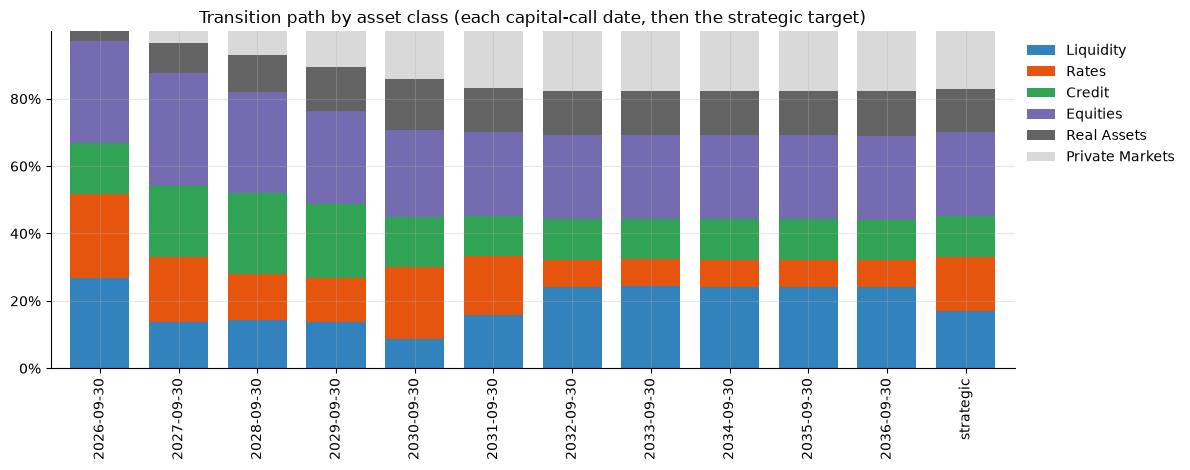

In [32]:
wpath = (
    proj.weights.T.groupby(cls)
    .sum()
    .T.loc[:, ["Liquidity", "Rates", "Credit", "Equities", "Real Assets", "Private Markets"]]
)
wpath.loc["strategic"] = by_class["strategic"]
fig, ax = plt.subplots(figsize=(12, 4.8))
wpath.plot.bar(stacked=True, ax=ax, colormap="tab20c", width=0.75)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title("Transition path by asset class (each capital-call date, then the strategic target)")
ax.legend(bbox_to_anchor=(1, 1), frameon=False)
ax.set_xlabel("")
plt.tight_layout()
plt.show()

**How to read the path:**

* **Year 0 (today):** cash drops from 45% to 20%, and equities, credit and gold are built in the
  liquid markets within the 30% turnover cap. Expected return rises by about 0.8%.
* **Years 1–5:** each year's calls are paid from the ladder. Liquidity and rates shrink step by step
  as private NAV grows. Expected return rises **above CPI + 3% from the first call date** and keeps
  rising toward the strategic level. Income rises toward 4.3%.
* **Around 2031:** the portfolio has reached the strategic allocation. After that the programme is
  in steady state, with commitments funded by distributions.

**Where does the money come from?** The fund plan shows sources (−) and uses (+) of every trade and
call, in USD m:

In [33]:
proj.funding_table().round(1).loc[lambda d: d.abs().max(axis=1) > 0.05]

date,2026-09-30,2027-09-30,2028-09-30,2029-09-30,2030-09-30,2031-09-30,2032-09-30,2033-09-30,2034-09-30,2035-09-30,2036-09-30
asset,,,,,,,,,,,
Cash,-25.0000,-13.9000,0.5000,0.7000,-1.3000,12.0000,13.0000,1.6000,0.8000,1.7000,0.8000
US STR,6.8000,0.5000,0.7000,-1.3000,-4.5000,-2.3000,-0.2000,-0.5000,0.0000,-0.7000,0.0000
US Govt,-5.0000,-5.8000,-9.8000,-6.1000,10.5000,-4.8000,-9.1000,0.1000,0.1000,0.1000,0.1000
UK Govt,0.0000,0.0000,3.7000,5.7000,0.2000,0.2000,-5.4000,0.4000,-1.2000,-0.8000,-2.7000
JP Govt,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.3000,-0.3000,1.3000,1.0000,2.9000
EM HC,3.0000,-0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
US IG,-0.0000,-5.3000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
EU IG,2.0000,5.3000,3.4000,0.1000,-4.0000,-3.6000,0.1000,0.1000,0.1000,0.1000,0.1000
US HY,2.0000,6.3000,-0.0000,-2.2000,-5.3000,0.0000,0.0000,0.0000,-0.0000,-0.0000,-0.0000


### 11.4 Sequencing, implementation and key risks

**Sequencing (proposed):**

| Phase | Timing | Actions |
|---|---|---|
| **0. Governance** | Month 0 | IC approves the SAA, ranges, rebalancing rule, pacing plan and liquidity policy. Confirm the open client-profile items (section 1). |
| **1. Liquid rebalance** | Months 0–6 | Diversify bonds and credit at once. Build **equities in 3–4 tranches** (dollar-cost averaging) to reduce timing risk; the 30% turnover cap per rebalance already forces at least two steps. Buy gold. Set up the **funding ladder** (cash, T-bills, IG/Treasuries by call date). |
| **2. Interim private proxies** | Months 0–24 | Hold **syndicated loans / HY** as a proxy for uncalled private debt, and **listed infrastructure** as a proxy for infrastructure, funded from the over-weights in cash and Treasuries. Sell them down as calls arrive. |
| **3. Private commitments** | Year 1 onward | Manager selection. Commit to private debt and infrastructure first (faster deployment, income), secondaries for PE. Follow the pacing plan each year, re-run yearly. |
| **4. Steady state** | From about 2031 | Re-commit from distributions. Rebalance the liquid book around the private NAV. Review the SAA yearly. |

**Key risks and mitigants:**

| Risk | What could happen | Mitigant in this framework |
|---|---|---|
| **Timing / entry** | Investing 30% of the book at one point in time | Tranches, a turnover cap, interim proxies |
| **Deployment** | Calls slower than planned → cash drag, return goal missed | Proxies hold the exposure. Re-pace commitments yearly. |
| **Liquidity** | Calls faster, or distributions stop, in a crisis | Funding ladder on net calls, stress tests (section 12) |
| **Denominator effect** | Public markets fall → private weight breaches its cap | 32% hard cap vs a 27% target leaves headroom. Monitored at each call date. |
| **Valuation / smoothing** | Private risk understated | Desmoothed and uplifted volatility in all risk numbers |
| **Assumption risk** | Return assumptions too optimistic | Sensitivity (section 7.4), goals with a margin, yearly review |
| **Manager / vintage concentration** | Small programme, few funds | Secondaries, fund-of-funds and evergreen vehicles, commitments every year |
| **Reinvestment / income** | Cash yield falls → income goal missed | Income moved to structural sources (credit, private debt, infrastructure) |

## 12. Liquidity management during deployment

### 12.1 Liquidity profile

For each portfolio on the path, `liquidity_profile` splits assets into **ladder / other liquid /
illiquid** and compares the ladder with the calls due in the next 1, 2 and 3 years, measured from
**that portfolio's own date and value**. A cover ≥ 1 means the ladder alone pays all upcoming calls,
with no sale of risky assets.

In [34]:
W_path = proj.weights.copy()
dates = {i: pd.Timestamp(i) for i in W_path.index}
pvs = path["portfolio_value"].to_dict()
lp = liquidity.liquidity_profile(W_path, u, schedule, pvs, dates)
pct(lp[["ladder", "other_liquid", "illiquid", "calls_1y", "calls_2y"]], 1).join(
    lp[["ladder_cover_1y", "ladder_cover_2y", "liquid_cover_1y"]].round(1)
)

,ladder,other_liquid,illiquid,calls_1y,calls_2y,ladder_cover_1y,ladder_cover_2y,liquid_cover_1y
2026-09-30,59.8%,40.2%,0.0%,5.7%,12.5%,10.5000,4.8000,17.6000
2027-09-30,35.9%,58.7%,5.4%,6.4%,14.3%,5.6000,2.5000,14.7000
2028-09-30,27.7%,61.3%,10.9%,7.4%,16.8%,3.8000,1.7000,12.1000
2029-09-30,21.7%,61.8%,16.5%,8.8%,18.3%,2.5000,1.2000,9.5000
2030-09-30,25.0%,52.7%,22.2%,8.9%,16.4%,2.8000,1.5000,8.7000
2031-09-30,28.2%,45.2%,26.6%,7.0%,14.2%,4.0000,2.0000,10.5000
2032-09-30,30.2%,42.0%,27.8%,6.8%,14.9%,4.5000,2.0000,10.7000
2033-09-30,30.3%,42.0%,27.7%,7.6%,16.1%,4.0000,1.9000,9.5000
2034-09-30,30.2%,42.0%,27.8%,7.9%,16.6%,3.8000,1.8000,9.1000
2035-09-30,30.2%,42.0%,27.8%,8.1%,8.1%,3.7000,3.7000,8.9000


Even at the peak of the J-curve, **more than 70% of the portfolio stays liquid** and the ladder
covers the next year's gross calls several times over. Liquidity is never the binding constraint in
the base case.

### 12.2 Stress tests of the deployment plan

The base case assumes that calls and distributions arrive as planned. We stress the **5-year
deployment period** (the calls of the first five years) with two standard cases:

1. **Distributions stop** for the whole deployment period (as in 2008–09 or 2022, but longer):
   private funds pay nothing out, calls continue.
2. **Calls arrive one year early** (managers deploy faster than expected), while the ladder was
   sized for the original plan, so the early calls are a surprise.

For each case we track: whether calls could be paid without an overdraft, the illiquid share against
its 32% cap, and whether the goals are still met.

In [35]:
DEPLOY_END = asof + pd.DateOffset(years=5) + pd.offsets.MonthEnd(0)
sched_5y = schedule[pd.to_datetime(schedule["date"]) <= DEPLOY_END]
net_5y = net_schedule[pd.to_datetime(net_schedule["date"]) <= DEPLOY_END]

In [36]:
def stress_summary(p, label):
    pth = p.allocations[["exp_return", "vol"]].copy()
    pth["illiquid"] = p.weights[priv].sum(axis=1)
    pth["goals_met"] = p.allocations["rule"].str.startswith("return+income met")
    unfunded = float(p.private_book["calls_unfunded"].sum()) if "calls_unfunded" in p.private_book else 0.0
    return dict(
        case=label,
        max_illiquid=pth["illiquid"].max(),
        min_exp_return=pth["exp_return"].iloc[1:].min(),
        max_vol=pth["vol"].max(),
        dates_goals_met=f"{int(pth['goals_met'].sum())}/{len(pth)}",
        unfunded_calls_usd=unfunded,
        cap_breaches=sum("breaches" in n for n in p.notes),
    )


p_base = CallDateProjector(data_t).run(schedule=sched_5y, planning_schedule=net_5y)
p_nodist = CallDateProjector(data_t).run(schedule=sched_5y, planning_schedule=net_5y, distributions=False)
early = sched_5y.assign(date=pd.to_datetime(sched_5y["date"]) - pd.DateOffset(years=1))
early = early[early["date"] > asof]
p_early = CallDateProjector(data_t).run(schedule=early, planning_schedule=net_5y)

st_tbl = pd.DataFrame(
    [
        stress_summary(p_base, "base case"),
        stress_summary(p_nodist, "no distributions"),
        stress_summary(p_early, "calls 1 year early"),
    ]
).set_index("case")
display(
    pct(st_tbl[["max_illiquid", "min_exp_return", "max_vol"]], 2).join(
        st_tbl[["dates_goals_met", "unfunded_calls_usd", "cap_breaches"]]
    )
)
for n in p_nodist.notes:
    if "breach" in n or "infeasible" in n or "unfunded" in n:
        print("no distributions:", n)

,max_illiquid,min_exp_return,max_vol,dates_goals_met,unfunded_calls_usd,cap_breaches
case,,,,,,
base case,26.62%,6.30%,6.17%,5/6,0.0000,0
no distributions,36.50%,6.30%,6.50%,5/6,0.0000,1
calls 1 year early,25.94%,6.26%,6.00%,4/5,0.0000,0


no distributions: 2031-09-30: private NAV breaches 'Private Markets' (36.50% > 32.00%)


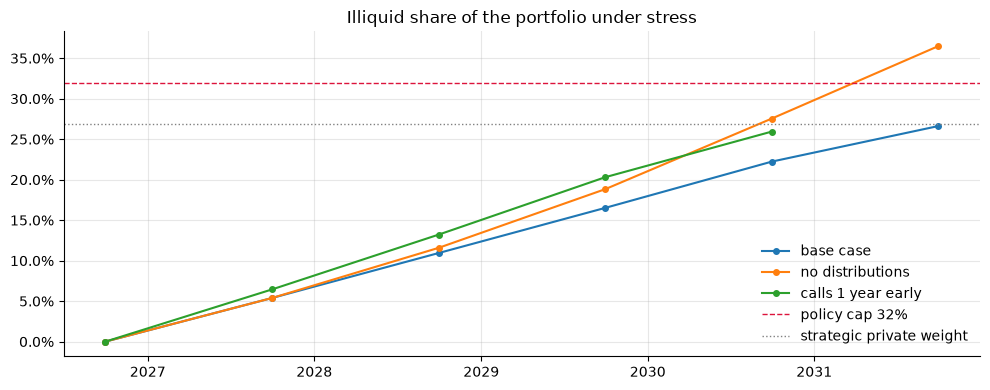

In [37]:
fig, ax = plt.subplots(figsize=(10, 4))
for p, lab in ((p_base, "base case"), (p_nodist, "no distributions"), (p_early, "calls 1 year early")):
    s = p.weights[priv].sum(axis=1)
    ax.plot(pd.to_datetime(s.index), s.values, "-o", ms=4, label=lab)
ax.axhline(0.32, color="crimson", ls="--", lw=1, label="policy cap 32%")
ax.axhline(w_saa[priv].sum(), color="grey", ls=":", lw=1, label="strategic private weight")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title("Illiquid share of the portfolio under stress")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Reading the stress tests:**

* **No calls go unfunded** in any case: the liquid book is always large enough. (The stress runs
  cover the 5 deployment years. A 10-year distribution freeze would push private NAV beyond any
  sensible cap, which is not a realistic scenario.)
* **Distributions stop.** This is the dangerous case. Private NAV keeps growing while calls continue,
  so the illiquid share rises toward and past the 32% cap a few years out. The defence is to **slow
  new commitments**. The pacing plan is re-run every year from the actual NAV and undrawn amounts, so
  a drought automatically lowers the next commitments.
* **Early calls** are mostly a *timing* issue. The ladder and the liquid book absorb the surprise,
  no call goes unfunded, and the goals are still met at every call date.

### 12.3 Liquidity policy (proposed)

1. **Funding ladder.** Pre-fund 100% of net calls due within 2 years in cash, 2–3 years in T-bills,
   and 3+ years in IG/Treasuries. Re-size it at every call date.
2. **Liquidity floor.** At least 60% of assets liquid within 1 month, at all times.
3. **Illiquid cap.** 32% of NAV (hard), against a 27% target. New commitments stop if the projected
   share exceeds 30%.
4. **Undrawn coverage.** Ladder + IG/Treasuries ≥ 1.5× undrawn commitments.
5. **Yearly re-pacing.** Re-run section 9 with the actual NAV, undrawn amounts and distributions;
   commit only the gap.
6. **Contingency sources**, in order: cash → T-bills → IG/Treasuries → interim proxies (loans,
   listed infrastructure) → rebalancing out of equities. Never a forced sale of private assets on the
   secondary market.

## 13. What can go wrong? Market stress and expected wealth

### 13.1 Factor stress scenarios

`FactorStress` estimates each asset's sensitivity (beta) to five factors (global equity, EUR/USD,
oil, global government bonds, global credit) on desmoothed quarterly data, then applies named shocks.
Correlated assets move through their betas. For example, an equity shock also hits credit and
private equity.

,current,today,strategic
scenario,,,
Equities -10%,-1.8%,-3.5%,-3.5%
Equities +10%,1.8%,3.5%,3.5%
EUR -10% vs USD,2.0%,3.7%,3.2%
EUR +10% vs USD,-2.0%,-3.7%,-3.2%
Oil price shock +50%,-0.2%,0.6%,1.7%
Rates shock (govt bonds -8%),-5.8%,-7.4%,-5.2%
Credit spread widening,-3.3%,-5.4%,-4.9%
Stagflation,-5.4%,-7.7%,-5.8%
Historical episode 1 (simulated),-3.9%,-6.2%,-5.3%


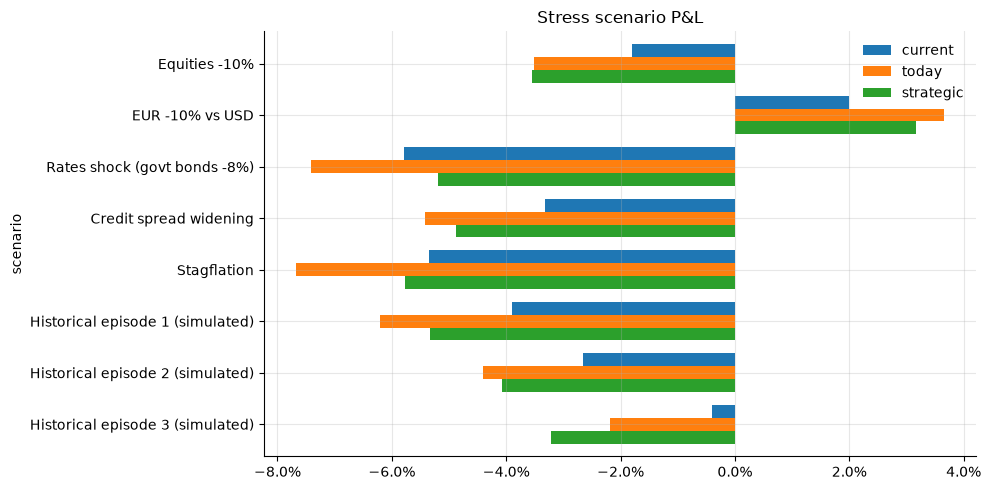

In [38]:
pf = {"current": w_cur, "today": alloc.today.weights, "strategic": w_saa.values}
fs = stress.FactorStress(u, data.common_returns, data.stress_factors)
pnl, _ = fs.run(stress.scenario_shocks(data.stress_scenarios, data.stress_factors), pf)
display(pct(pnl, 1))

fig, ax = plt.subplots(figsize=(10, 5))
pnl.loc[~pnl.index.str.contains(r"\+")].plot.barh(ax=ax, width=0.75)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title("Stress scenario P&L")
ax.legend(frameon=False)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

The strategic portfolio loses more than the current one in equity and credit shocks (it takes more
risk, deliberately). It loses about as much in a rates shock, because it holds less duration.
Stagflation and a rates shock are the worst cases for the strategic target, at roughly −5% to −6%.
That is the order of magnitude to discuss with the client as a *bad year*.

**Today's** portfolio is the most exposed during the transition (−7.7% in stagflation, −7.4% in a
rates shock). It still holds a lot of duration, now combined with new equity and credit risk. This
is one more reason to phase the equity build and to move toward the strategic mix promptly.

### 13.2 Historical episodes and pro-forma performance

Each portfolio is held at fixed weights through the (simulated) history:

In [39]:
R = data.common_returns[u.names]
pro = performance_table(pd.DataFrame({p: R.values @ np.asarray(w) for p, w in pf.items()}, index=R.index))
display(
    pct(pro[["ann_return", "ann_vol", "max_drawdown", "var_95_monthly", "worst_month"]], 2).join(
        pro[["sharpe"]].round(2)
    )
)
eps = stress.historical_episodes(R, pf, reference="strategic")
pct(eps.pivot_table(index="episode", columns="portfolio", values="cum_return"), 1)

,ann_return,ann_vol,max_drawdown,var_95_monthly,worst_month,sharpe
current,4.89%,3.49%,-4.28%,1.05%,-2.96%,1.3900
today,5.56%,5.82%,-8.09%,2.02%,-4.97%,0.9600
strategic,6.62%,4.71%,-5.89%,1.64%,-3.53%,1.3900


portfolio,current,strategic,today
episode,,,
China / oil slump,-0.3%,-0.4%,-1.5%
Covid crash,2.3%,2.8%,3.0%
Euro sovereign crisis,4.4%,4.6%,5.6%
Q4 2018 sell-off,2.3%,3.5%,3.7%
Rates shock 2022,4.1%,2.1%,2.5%
Taper tantrum,0.6%,1.6%,1.2%
worst 12m #1 (strategic),0.1%,-5.5%,-5.3%
worst 12m #2 (strategic),-0.7%,-2.6%,-4.0%


### 13.3 Wealth projection: probability of meeting CPI + 3% over 10 years

A Monte Carlo simulation (5,000 paths, joint lognormal returns calibrated to the assumptions and the
covariance) follows the **projected allocation path** of section 11, not a static target. It reports
the distribution of wealth and the probability of compounding at or above the return goal.

,p5,p25,p50,p75,p95,p_beat_target,p_nominal_loss,p_real_loss
year,,,,,,,,
1,96.1,101.5,105.7,109.9,116.6,47%,17%,35%
3,99.8,110.9,118.9,127.8,141.6,47%,5%,23%
5,107.5,122.6,134.2,147.2,169.3,48%,1%,16%
10,134.1,161.1,182.8,208.7,251.1,49%,0%,6%


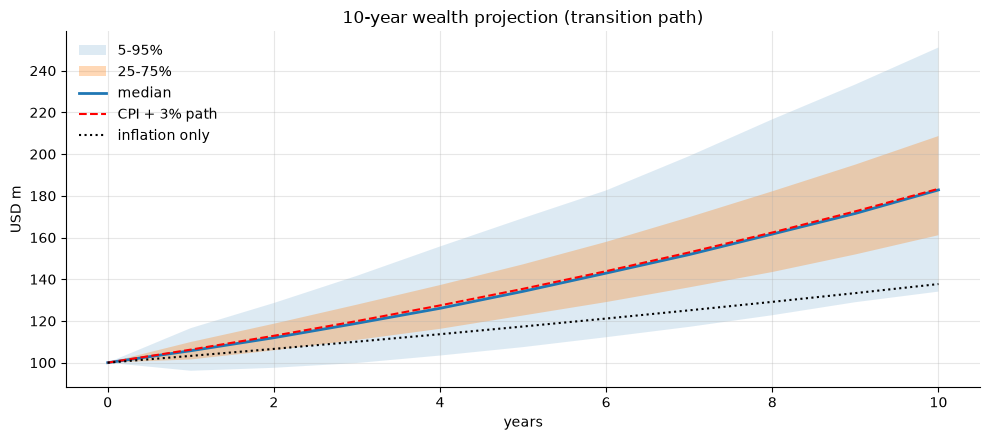

In [40]:
wp_path = proj.weights.copy()
wp_path.index = pd.to_datetime(wp_path.index)
wp = simulate_wealth(
    u.mu,
    S.values,
    wp_path,
    years=10,
    n_paths=5000,
    start_value=PV0,
    cpi=state.goals.cpi,
    target_return=goals.target_return,
    start=asof,
)
tbl = mio(wp.percentiles[["p5", "p25", "p50", "p75", "p95"]]).join(pct(wp.probabilities, 0))
display(tbl.loc[[1, 3, 5, 10]])

fig, ax = plt.subplots(figsize=(10, 4.5))
q = wp.percentiles / 1e6
ax.fill_between(q.index, q["p5"], q["p95"], alpha=0.15, label="5-95%")
ax.fill_between(q.index, q["p25"], q["p75"], alpha=0.3, label="25-75%")
ax.plot(q.index, q["p50"], lw=2, label="median")
ax.plot(q.index, PV0 / 1e6 * (1 + goals.target_return) ** q.index, "r--", label="CPI + 3% path")
ax.plot(q.index, PV0 / 1e6 * (1 + state.goals.cpi) ** q.index, "k:", label="inflation only")
ax.set_xlabel("years")
ax.set_ylabel("USD m")
ax.set_title("10-year wealth projection (transition path)")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

**Reading the projection:** the median ends close to the CPI + 3% path (slightly below it, because
the first year is still in transition). The probability of compounding at or above CPI + 3% is about
one half: the goal is close to the *expected* return, so a coin flip is the honest answer. The
probability of losing in **real** terms over 10 years is small, about 6%.

> **Fine print: stress and Monte Carlo**
>
> * **Factor stress is linear.** Asset moves are betas × factor shocks, with betas estimated on
>   desmoothed quarterly data. Non-linear effects (gating, forced sales, liquidity spirals) are not
>   captured; section 12 covers liquidity separately.
> * **Monte Carlo is lognormal.** It has no fat tails and no volatility clustering, and uses the
>   frozen expected returns and covariance. It **understates** crash probabilities. Read the 5th
>   percentile as a mild, not a severe, downside.
> * **The goal test is geometric.** `p_beat_target` compares *compounded* wealth with 1.0625^t. The
>   portfolio's geometric expected return (about 6.5%) is only slightly above 6.25%, which is why the
>   probability is close to 50%. These are the numbers to put in front of the client instead of a single volatility figure.


## Companion: the same case with semi-liquid funds (ELTIF)

This notebook implements private markets through **closed-end funds**: commitments, capital calls,
a pacing plan, recommitment and a funding ladder. The companion notebook
[`Cases_study_SAA_SemiLiquid_PrivateMarkets.ipynb`](Cases_study_SAA_SemiLiquid_PrivateMarkets.ipynb)
solves **the same case** with **semi-liquid evergreen funds (ELTIF)**:

* subscriptions at NAV, with no commitments, pacing plan or recommitment;
* redemptions limited by a gate;
* a liquidity sleeve and fee drag inside the fund.

It ends with a side-by-side comparison of the two vehicles.


## 14. Summary for the investment committee

In [41]:
summary = pd.DataFrame(
    {
        "current": stats(w_cur),
        "today (implementable)": stats(alloc.today.weights),
        "strategic target": stats(w_saa),
    }
).T
summary["meets return goal"] = summary["exp_return"] >= goals.target_return - 1e-6
summary["meets income goal (3.5%)"] = summary["income"] >= 0.035 - 1e-6
summary["vol in 6-8% band"] = summary["vol"].between(goals.vol_lo - 1e-6, goals.vol_hi + 1e-6)
display(pct(summary[["exp_return", "income", "vol", "illiquid"]], 2).join(summary.iloc[:, 4:]))
print(f"Goals first met on the transition path at: {first_met}")
print(
    f"Total commitments years 1-5: USD {commit_tbl['total'].iloc[:5].sum() / 1e6:,.1f}m; "
    f"peak cumulative net outflow (J-curve): USD {-cf_tbl['cum_net_cash_flow'].min() / 1e6:,.1f}m"
)
print(
    f"P(10y annualised return >= CPI+3%): {wp.probabilities.loc[10, 'p_beat_target']:.0%} | "
    f"P(real loss after 10y): {wp.probabilities.loc[10, 'p_real_loss']:.0%}"
)

,exp_return,income,vol,illiquid,meets return goal,meets income goal (3.5%),vol in 6-8% band
current,4.97%,3.46%,3.34%,0.00%,False,False,False
today (implementable),5.76%,3.46%,5.87%,0.00%,False,False,False
strategic target,6.70%,4.26%,6.00%,26.86%,True,True,True


Goals first met on the transition path at: 2027-09-30
Total commitments years 1-5: USD 48.4m; peak cumulative net outflow (J-curve): USD 31.5m
P(10y annualised return >= CPI+3%): 49% | P(real loss after 10y): 6%


### Recommendations

1. **Client profile.** Before final approval, confirm the investor type, the use of income (payout vs
   reinvested), the liquidity and illiquidity tolerance, FX hedging and implementation constraints
   (section 1).
2. **Strategic allocation.** Move from a 45% cash, US-only book to a diversified, goal-based SAA:
   about 17% liquidity, 16% rates, 12% credit, 25% global equities, 13% real assets (gold +
   infrastructure) and 17% private markets (private debt + PE). It targets about 6.7% expected return
   (> CPI + 3%), 4.3% income (> 3.5%) at 6% volatility, the bottom of the band, which leaves risk
   budget in reserve.
3. **Methodology.** Ranked goals (return → income → risk) instead of an abstract risk aversion.
   Desmoothed and uplifted private-market risk. Shrunk EWMA covariance. Hard policy limits. A
   transparent audit trail and sensitivity analysis.
4. **Transition.** Rebalance the liquid book now, within the 30% turnover cap and in tranches for
   equities. Hold interim proxies for private debt and infrastructure. Build the private programme
   over 5 years. The return goal is met from the first call date (2027), and the strategic mix is
   reached around 2031.
5. **Implementation.** Global equities with a quality/dividend tilt. Treasuries plus diversified
   government bonds. IG and sub-IG credit. Private debt mostly senior direct lending. Core and
   core-plus infrastructure. Secondaries and fund-of-funds for PE.
6. **Private markets and liquidity.** Commit about USD 7–14m a year in the first five years (about
   USD 48m in total, see the pacing table), re-paced yearly. A funding ladder pre-funds the net calls. An illiquid cap of 32%
   (target 27%) with a commitment brake at 30%. Stress-tested for a distribution freeze and
   accelerated calls.

7. **Vehicle choice.** Evaluate semi-liquid ELTIFs (companion notebook) for private equity and for the ramp-up phase.
   They remove recommitment and the J-curve, at the price of a cash and fee drag and a gate in
   stress.
8. **Data governance.** Run `data_check.py` on every data delivery. No FAIL may remain, and every
   WARN needs an explanation before the study is presented.

---

*All data in this notebook is simulated. The results illustrate the method and say nothing about
real markets. For research and educational use; not investment advice.*

**Next steps:** re-run this notebook with the house return assumptions and the client's real
holdings. To reproduce the full set of tables, charts and the Excel workbook for a folder of CSV
files, use `saa-pm run <folder> -o results` (see the README).